Subscription churn prediction

Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Load the data

viewing the data

In [ ]:
df=pd.read_csv("Subscription_Service_Churn_Dataset.csv")

In [ ]:
print(df.head())

   AccountAge  MonthlyCharges  TotalCharges SubscriptionType  \
0          42       11.321950    475.521914            Basic   
1          95       12.810915   1217.036887         Standard   
2           6             NaN     91.583304         Standard   
3          54       17.917819    967.562224            Basic   
4          27             NaN    339.057244            Basic   

      PaymentMethod PaperlessBilling ContentType MultiDeviceAccess  \
0  Electronic check              Yes      Movies               Yes   
1  Electronic check              Yes    TV Shows                No   
2       Credit card              Yes    TV Shows                No   
3               NaN              Yes      Movies                No   
4      Mailed check               No    TV Shows                No   

  DeviceRegistered  ViewingHoursPerWeek  ...  ContentDownloadsPerMonth  \
0           Tablet             0.386852  ...                        25   
1           Mobile            37.123000  ...  

In [ ]:
print(df.columns)

Index(['AccountAge', 'MonthlyCharges', 'TotalCharges', 'SubscriptionType',
       'PaymentMethod', 'PaperlessBilling', 'ContentType', 'MultiDeviceAccess',
       'DeviceRegistered', 'ViewingHoursPerWeek', 'AverageViewingDuration',
       'ContentDownloadsPerMonth', 'GenrePreference', 'UserRating',
       'SupportTicketsPerMonth', 'Gender', 'WatchlistSize', 'ParentalControl',
       'SubtitlesEnabled', 'CustomerID', 'Churn'],
      dtype='object')


In [ ]:
print(df.shape)

(963, 21)


In [ ]:
print(df.dtypes)

AccountAge                    int64
MonthlyCharges              float64
TotalCharges                float64
SubscriptionType             object
PaymentMethod                object
PaperlessBilling             object
ContentType                  object
MultiDeviceAccess            object
DeviceRegistered             object
ViewingHoursPerWeek         float64
AverageViewingDuration      float64
ContentDownloadsPerMonth      int64
GenrePreference              object
UserRating                  float64
SupportTicketsPerMonth        int64
Gender                       object
WatchlistSize                 int64
ParentalControl              object
SubtitlesEnabled             object
CustomerID                   object
Churn                         int64
dtype: object


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 963 entries, 0 to 962
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   AccountAge                963 non-null    int64  
 1   MonthlyCharges            759 non-null    float64
 2   TotalCharges              777 non-null    float64
 3   SubscriptionType          913 non-null    object 
 4   PaymentMethod             740 non-null    object 
 5   PaperlessBilling          963 non-null    object 
 6   ContentType               963 non-null    object 
 7   MultiDeviceAccess         963 non-null    object 
 8   DeviceRegistered          887 non-null    object 
 9   ViewingHoursPerWeek       963 non-null    float64
 10  AverageViewingDuration    963 non-null    float64
 11  ContentDownloadsPerMonth  963 non-null    int64  
 12  GenrePreference           853 non-null    object 
 13  UserRating                702 non-null    float64
 14  SupportTic

In [ ]:
df.describe()

,AccountAge,MonthlyCharges,TotalCharges,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,UserRating,SupportTicketsPerMonth,WatchlistSize,Churn
count,963.000000,759.000000,777.000000,963.000000,963.000000,963.000000,702.000000,963.000000,963.000000,963.000000
mean,57.515057,12.328262,714.052121,21.029241,90.741877,24.694704,2.923945,4.455867,11.900312,0.175493
std,33.662575,4.260861,511.071322,11.318164,49.923719,14.319572,1.165992,2.935706,7.117402,0.380586
min,1.000000,5.062339,11.582882,0.315317,5.028412,0.000000,1.000181,0.000000,0.000000,0.000000
25%,29.000000,8.816669,318.425396,11.621961,47.777701,13.000000,1.922235,2.000000,6.000000,0.000000
50%,55.000000,12.169888,614.196606,21.334100,89.878241,25.000000,2.898328,5.000000,12.000000,0.000000
75%,86.000000,15.937606,1021.436452,30.419851,134.353824,37.000000,3.953953,7.000000,18.000000,0.000000
max,119.000000,19.932542,2261.019201,39.949086,179.752024,49.000000,4.997348,9.000000,24.000000,1.000000


In [ ]:
df.isnull()

,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,CustomerID,Churn
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,True,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
3,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
959,False,False,False,False,True,False,False,False,False,False,...,False,True,True,False,False,False,False,True,False,False
960,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
961,False,False,True,False,True,False,False,False,False,False,...,False,False,True,False,False,False,False,True,False,False


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum().sum()

np.int64(1950)

In [ ]:
df[df['MonthlyCharges'].isna()]

,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,CustomerID,Churn
2,6,NaN,91.583304,Standard,Credit card,Yes,TV Shows,No,Tablet,30.716944,...,29,Fantasy,NaN,4,Male,14,No,Yes,JB5J8X2UY1,1
4,27,NaN,339.057244,Basic,Mailed check,No,TV Shows,No,Mobile,39.936910,...,44,Comedy,3.236230,4,Female,18,No,NaN,B3BDJTW0L9,0
5,71,NaN,818.287054,Premium,Credit card,No,Movies,Yes,Computer,7.310172,...,30,Comedy,2.779614,6,Female,16,Yes,NaN,5E4TQK5OVX,0
8,8,NaN,NaN,Premium,Electronic check,No,Both,Yes,Computer,15.488913,...,16,Fantasy,NaN,3,Female,2,No,Yes,IGZ39O1ROC,0
10,102,NaN,1954.784656,Premium,NaN,No,Movies,Yes,Mobile,38.919239,...,29,NaN,2.683853,6,Male,19,Yes,Yes,W636FZ4VNV,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
945,39,NaN,364.320544,Basic,Credit card,No,Both,Yes,Computer,11.299914,...,29,Drama,1.378773,6,Female,14,Yes,NaN,074PZ3GZSG,0
948,63,NaN,915.751142,Premium,Credit card,Yes,TV Shows,Yes,Mobile,12.312192,...,29,NaN,2.126789,2,Male,17,No,NaN,XW3KL8GLF1,0
950,30,NaN,NaN,Standard,NaN,No,TV Shows,Yes,Mobile,21.738853,...,9,Action,4.227247,7,Male,11,Yes,NaN,ZZ2AOBLX7L,1
952,22,NaN,NaN,Standard,Electronic check,No,TV Shows,Yes,Mobile,28.158003,...,4,Sci-Fi,1.437629,7,Male,24,No,NaN,GEF3YMDT2A,0


In [ ]:
df.dropna(axis=1)

,AccountAge,PaperlessBilling,ContentType,MultiDeviceAccess,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,SupportTicketsPerMonth,WatchlistSize,ParentalControl,CustomerID,Churn
0,42,Yes,Movies,Yes,0.386852,24.593361,25,7,15,No,LOHRYYC9E8,0
1,95,Yes,TV Shows,No,37.123000,102.860795,21,3,8,No,RIH7RFEZCS,0
2,6,Yes,TV Shows,No,30.716944,10.512415,29,4,14,No,JB5J8X2UY1,1
3,54,Yes,Movies,No,2.495373,45.246834,45,3,12,No,Z4GZJIB90P,0
4,27,No,TV Shows,No,39.936910,94.310954,44,4,18,No,B3BDJTW0L9,0
...,...,...,...,...,...,...,...,...,...,...,...,...
958,83,No,Movies,No,2.520628,45.949435,40,9,21,Yes,AV3ZDGUB4C,0
959,67,Yes,TV Shows,No,3.737329,25.272097,40,1,22,No,15GWB8NVG5,0
960,119,Yes,TV Shows,Yes,5.691826,38.849305,5,2,23,No,6VUYH24HVW,0
961,57,Yes,Movies,No,30.267865,125.147142,40,0,14,No,X1OE7MMFDL,0


In [ ]:
df['MonthlyCharges']=df['MonthlyCharges'].fillna(df['MonthlyCharges'].mean())

In [ ]:
df['TotalCharges']=df['TotalCharges'].fillna(df['TotalCharges'].mean())


In [ ]:
df['ViewingHoursPerWeek']=df['ViewingHoursPerWeek'].fillna(df['ViewingHoursPerWeek'].mean())

In [ ]:
df['UserRating']=df['UserRating'].fillna(df['UserRating'].mean())


In [ ]:
df['SubscriptionType']=df['SubscriptionType'].fillna(df['SubscriptionType'].mode()[0])

In [ ]:
df['PaymentMethod']=df['PaymentMethod'].fillna(df['PaymentMethod'].mode()[0])

In [ ]:
df['DeviceRegistered']=df['DeviceRegistered'].fillna(df['DeviceRegistered'].mode()[0])

In [ ]:
df['GenrePreference']=df['GenrePreference'].fillna(df['GenrePreference'].mode()[0])

In [ ]:
df['Gender']=df['Gender'].fillna(df['Gender'].mode()[0])

In [ ]:
df['SubtitlesEnabled']=df['SubtitlesEnabled'].fillna(df['SubtitlesEnabled'].mode()[0])

In [ ]:
df['CustomerID']=df['CustomerID'].fillna(df['CustomerID'].mode()[0])

In [ ]:
df.drop("CustomerID", axis=1, inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 963 entries, 0 to 962
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   AccountAge                963 non-null    int64  
 1   MonthlyCharges            963 non-null    float64
 2   TotalCharges              963 non-null    float64
 3   SubscriptionType          963 non-null    object 
 4   PaymentMethod             963 non-null    object 
 5   PaperlessBilling          963 non-null    object 
 6   ContentType               963 non-null    object 
 7   MultiDeviceAccess         963 non-null    object 
 8   DeviceRegistered          963 non-null    object 
 9   ViewingHoursPerWeek       963 non-null    float64
 10  AverageViewingDuration    963 non-null    float64
 11  ContentDownloadsPerMonth  963 non-null    int64  
 12  GenrePreference           963 non-null    object 
 13  UserRating                963 non-null    float64
 14  SupportTic

In [ ]:
df.to_csv("Subscription_Service_Churn_Cleaned_Dataset.csv", index=False)

Outlier detection

Box plot

In [ ]:
# Exclude target variable
outlier_cols = df.select_dtypes(include=np.number).columns.drop("Churn")

print("Columns used for outlier detection:")
print(list(outlier_cols))

Columns used for outlier detection:
['AccountAge', 'MonthlyCharges', 'TotalCharges', 'ViewingHoursPerWeek', 'AverageViewingDuration', 'ContentDownloadsPerMonth', 'UserRating', 'SupportTicketsPerMonth', 'WatchlistSize']


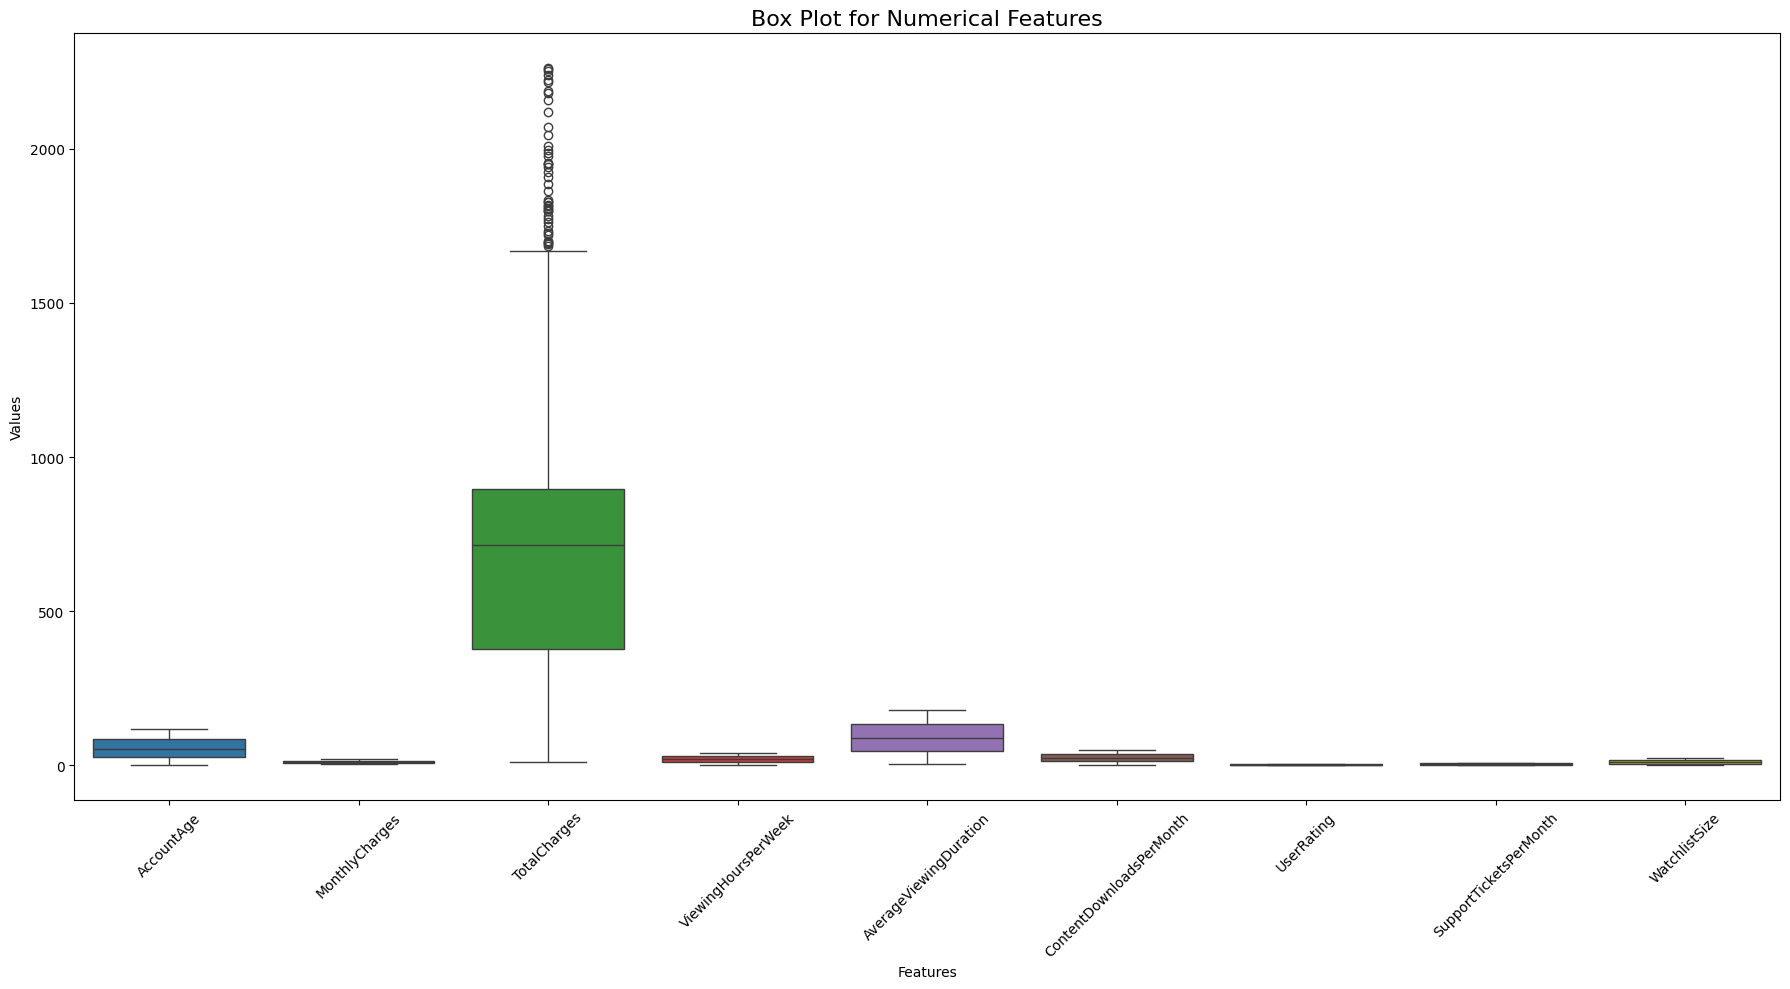

In [ ]:
plt.figure(figsize=(18, 10))

sns.boxplot(data=df[outlier_cols])

plt.title("Box Plot for Numerical Features", fontsize=16)
plt.xlabel("Features")
plt.ylabel("Values")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# IQR Outlier Detection

iqr_results = []

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    iqr_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (len(outliers) / len(df)) * 100
    })

iqr_summary = pd.DataFrame(iqr_results)

display(iqr_summary)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,AccountAge,29.000000,86.000000,57.000000,-56.500000,171.500000,0,0.000000
1,MonthlyCharges,9.576123,15.012909,5.436786,1.420944,23.168088,0,0.000000
2,TotalCharges,377.052449,895.658870,518.606421,-400.857183,1673.568502,45,4.672897
3,ViewingHoursPerWeek,11.621961,30.419851,18.797890,-16.574873,58.616685,0,0.000000
4,AverageViewingDuration,47.777701,134.353824,86.576123,-82.086483,264.218008,0,0.000000
5,ContentDownloadsPerMonth,13.000000,37.000000,24.000000,-23.000000,73.000000,0,0.000000
6,UserRating,2.275808,3.522727,1.246920,0.405428,5.393107,0,0.000000
7,SupportTicketsPerMonth,2.000000,7.000000,5.000000,-5.500000,14.500000,0,0.000000
8,WatchlistSize,6.000000,18.000000,12.000000,-12.000000,36.000000,0,0.000000


In [ ]:
iqr_outliers_only = iqr_summary[iqr_summary["Outlier Count"] > 0]

print("Features containing IQR outliers:")
display(iqr_outliers_only)

Features containing IQR outliers:


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
2,TotalCharges,377.052449,895.65887,518.606421,-400.857183,1673.568502,45,4.672897


Outlier detection

Z score

In [ ]:
from scipy.stats import zscore
# Calculate Z-scores
z_scores = df[outlier_cols].apply(zscore)

# Identify outliers
z_outlier_mask = z_scores.abs() > 3

# Count outliers in each column
z_outlier_count = z_outlier_mask.sum()

z_summary = pd.DataFrame({
    "Feature": outlier_cols,
    "Outlier Count": z_outlier_count.values,
    "Outlier Percentage":
        (z_outlier_count.values / len(df)) * 100
})

display(z_summary)

,Feature,Outlier Count,Outlier Percentage
0,AccountAge,0,0.000000
1,MonthlyCharges,0,0.000000
2,TotalCharges,10,1.038422
3,ViewingHoursPerWeek,0,0.000000
4,AverageViewingDuration,0,0.000000
5,ContentDownloadsPerMonth,0,0.000000
6,UserRating,0,0.000000
7,SupportTicketsPerMonth,0,0.000000
8,WatchlistSize,0,0.000000


In [ ]:
z_outliers_only = z_summary[z_summary["Outlier Count"] > 0]

print("Features containing Z-score outliers:")
display(z_outliers_only)

Features containing Z-score outliers:


,Feature,Outlier Count,Outlier Percentage
2,TotalCharges,10,1.038422


Week 4:EDA DEEP DRIVE.Univariate and Bivariate analysis.Visualizing distributions.

**Account Age:**

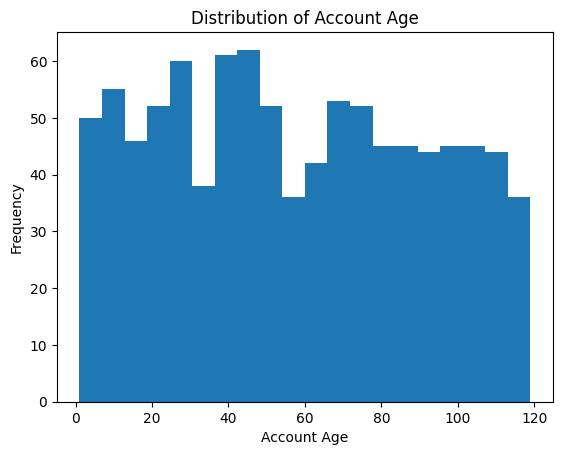

In [ ]:
df1 = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.hist(df1["AccountAge"], bins=20)
plt.xlabel("Account Age")
plt.ylabel("Frequency")
plt.title("Distribution of Account Age")
plt.show()

**Distribution of Monthly Charges:**

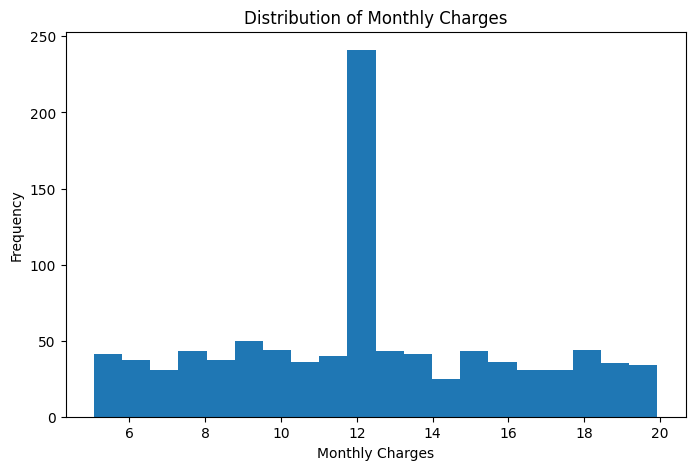

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.hist(df["MonthlyCharges"], bins=20)
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")
plt.title("Distribution of Monthly Charges")
plt.show()

**User Rating:**

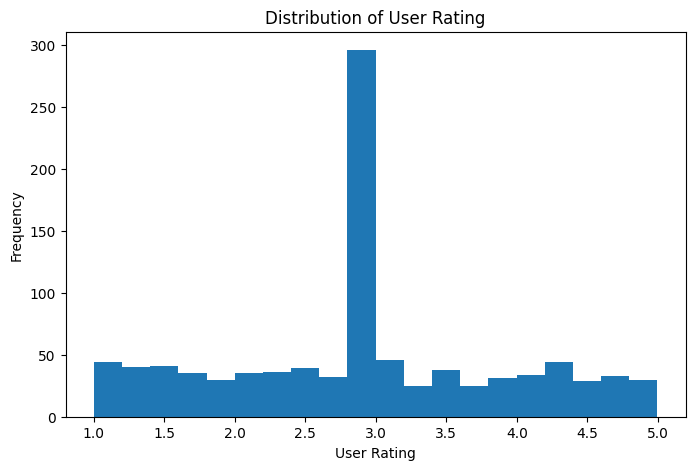

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.hist(df["UserRating"], bins=20)
plt.xlabel("User Rating")
plt.ylabel("Frequency")
plt.title("Distribution of User Rating")
plt.show()

**Average Viewing Duration:**

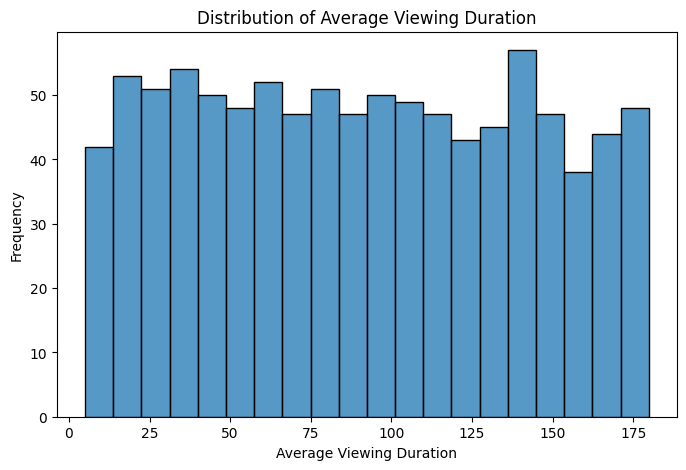

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
sns.histplot(df["AverageViewingDuration"], bins=20)
plt.xlabel("Average Viewing Duration")
plt.ylabel("Frequency")
plt.title("Distribution of Average Viewing Duration")
plt.show()

**Subscription Type:**

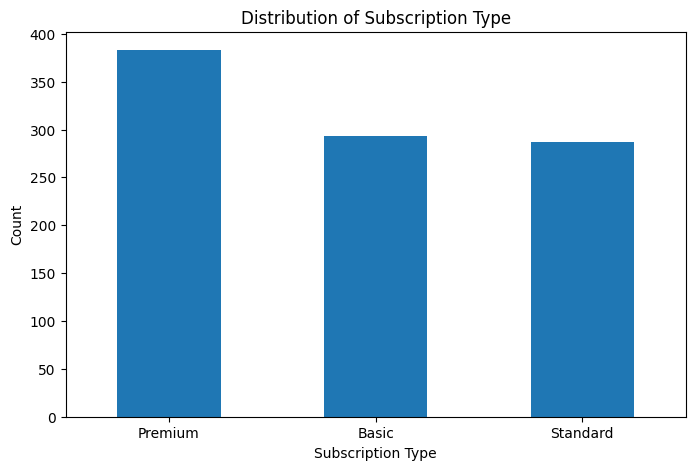

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["SubscriptionType"].value_counts().plot(kind="bar")
plt.xlabel("Subscription Type")
plt.ylabel("Count")
plt.title("Distribution of Subscription Type")
plt.xticks(rotation=0)
plt.show()

**Payment Method:**

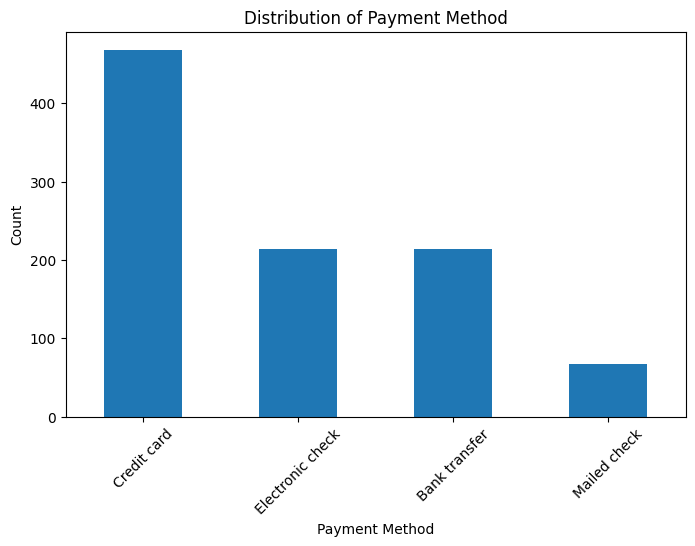

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["PaymentMethod"].value_counts().plot(kind="bar")
plt.xlabel("Payment Method")
plt.ylabel("Count")
plt.title("Distribution of Payment Method")
plt.xticks(rotation=45)
plt.show()

**Genre Preference:**

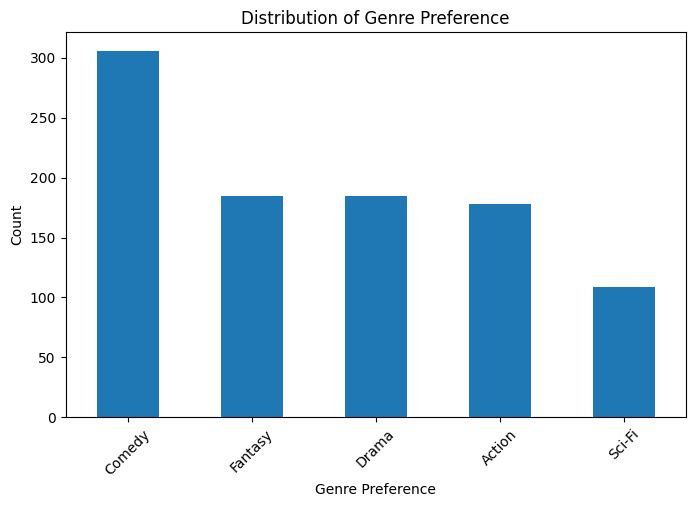

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["GenrePreference"].value_counts().plot(kind="bar")
plt.xlabel("Genre Preference")
plt.ylabel("Count")
plt.title("Distribution of Genre Preference")
plt.xticks(rotation=45)
plt.show()

**Gender:**

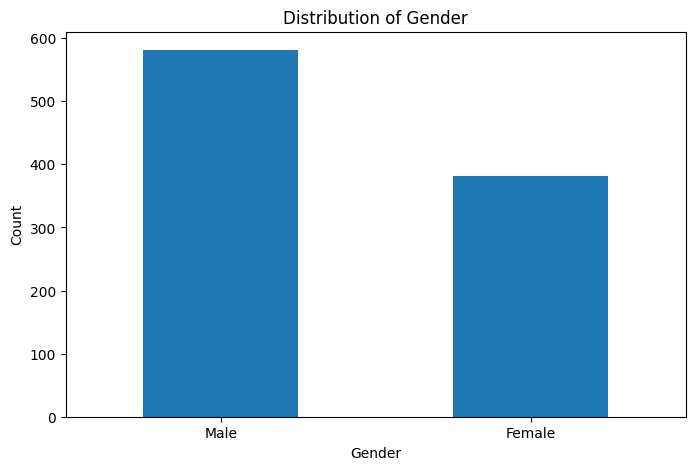

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["Gender"].value_counts().plot(kind="bar")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Distribution of Gender")
plt.xticks(rotation=0)
plt.show()

**SubtitlesEnabled:**

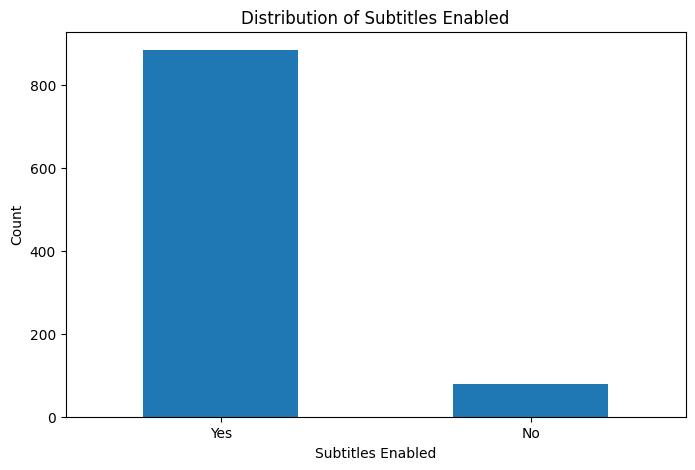

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["SubtitlesEnabled"].value_counts().plot(kind="bar")
plt.xlabel("Subtitles Enabled")
plt.ylabel("Count")
plt.title("Distribution of Subtitles Enabled")
plt.xticks(rotation=0)
plt.show()

**Churn:**

**Bivariate Analysis:**

**Bar Plot — SubscriptionType vs Churn:**

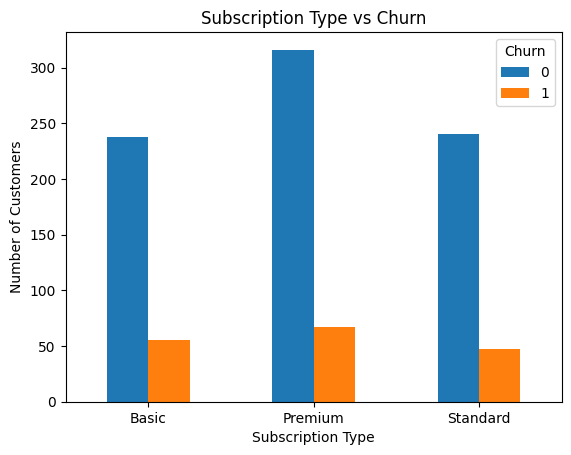

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

pd.crosstab(df["SubscriptionType"], df["Churn"]).plot(kind="bar")

plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")
plt.title("Subscription Type vs Churn")
plt.xticks(rotation=0)
plt.show()

**PaymentMethod vs Churn:**

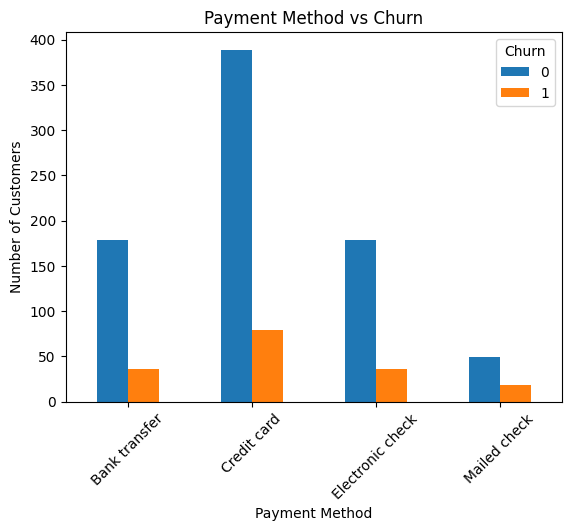

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

pd.crosstab(df["PaymentMethod"], df["Churn"]).plot(kind="bar")

plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.title("Payment Method vs Churn")
plt.xticks(rotation=45)
plt.show()

**SubscriptionType vs PaymentMethod:**

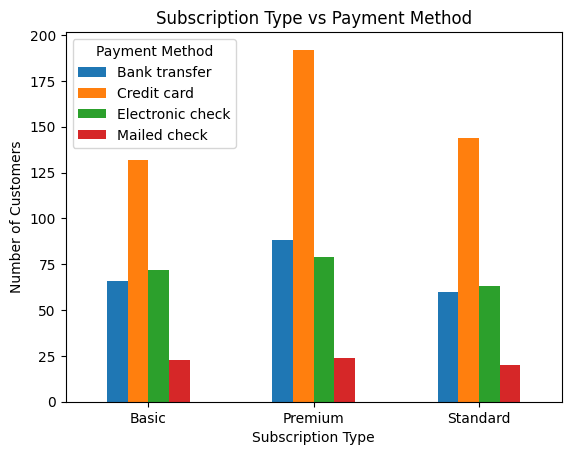

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

pd.crosstab(df["SubscriptionType"], df["PaymentMethod"]).plot(kind="bar")

plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")
plt.title("Subscription Type vs Payment Method")
plt.xticks(rotation=0)
plt.legend(title="Payment Method")
plt.show()

**DeviceRegistered vs MultiDeviceAccess:**

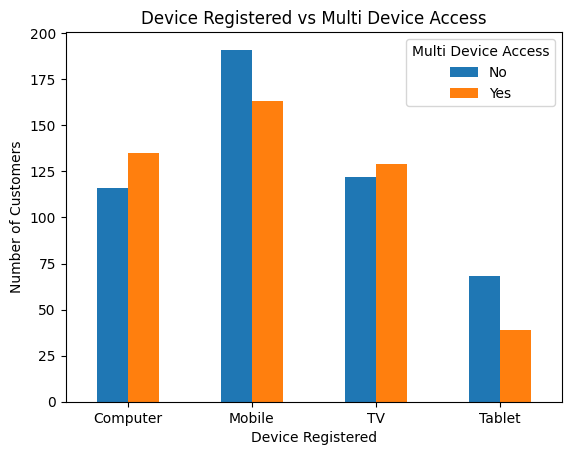

In [ ]:

df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

pd.crosstab(df["DeviceRegistered"], df["MultiDeviceAccess"]).plot(kind="bar")

plt.xlabel("Device Registered")
plt.ylabel("Number of Customers")
plt.title("Device Registered vs Multi Device Access")
plt.xticks(rotation=0)
plt.legend(title="Multi Device Access")
plt.show()

**Account Age vs Total Charges:**

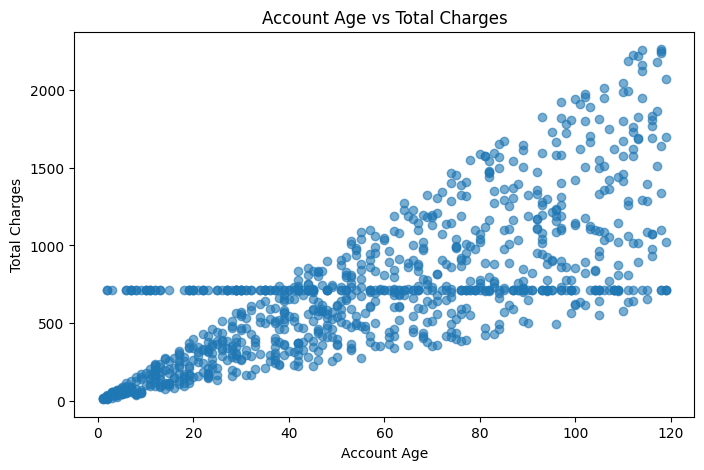

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.scatter(df["AccountAge"], df["TotalCharges"], alpha=0.6)

plt.xlabel("Account Age")
plt.ylabel("Total Charges")
plt.title("Account Age vs Total Charges")
plt.show()

**MonthlyCharges vs TotalCharges:**

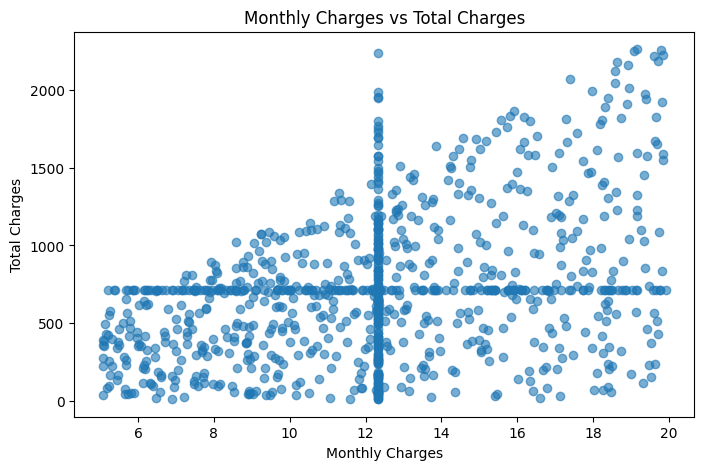

In [ ]:


df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.scatter(df["MonthlyCharges"], df["TotalCharges"], alpha=0.6)

plt.xlabel("Monthly Charges")
plt.ylabel("Total Charges")
plt.title("Monthly Charges vs Total Charges")
plt.show()

**Content Type vs Viewing Hours:**

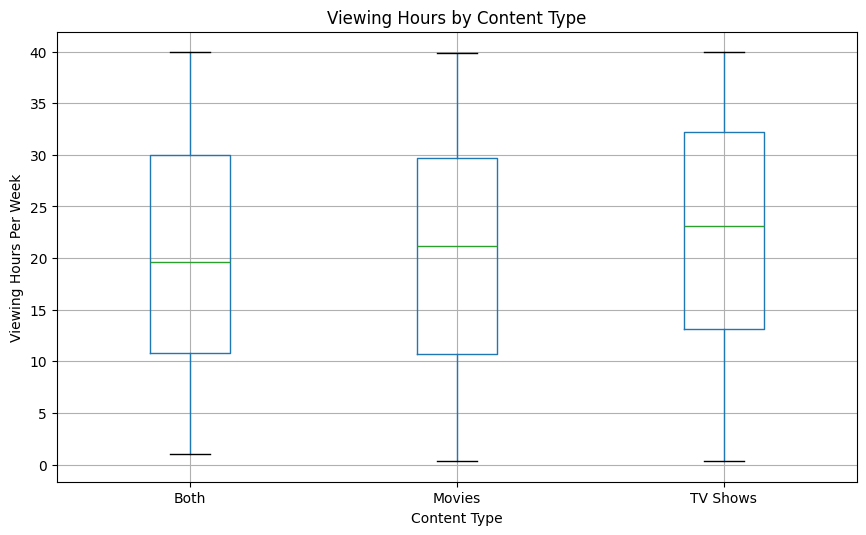

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

df.boxplot(column="ViewingHoursPerWeek", by="ContentType", figsize=(10,6))

plt.xlabel("Content Type")
plt.ylabel("Viewing Hours Per Week")
plt.title("Viewing Hours by Content Type")
plt.suptitle("")
plt.show()

**Gender vs User Rating:**

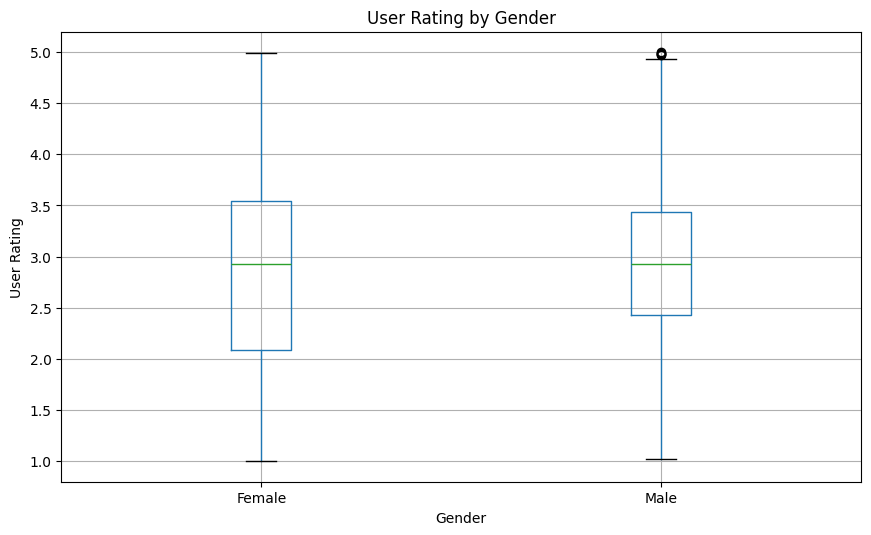

In [ ]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

df.boxplot(column="UserRating", by="Gender", figsize=(10,6))

plt.xlabel("Gender")
plt.ylabel("User Rating")
plt.title("User Rating by Gender")
plt.suptitle("")
plt.show()

WEEK 6

NORMALIZATION, SCALING, AND ENCODING CATEGORICAL VARIABLES. FIXING SKEWNESS

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import pandas as pd

df = pd.read_csv(list(uploaded.keys())[0])

print("First 5 Rows:")
display(df.head())

print("Dataset Shape (Rows, Columns):")
print(df.shape)

print("Column Names:")
print(df.columns.tolist())


First 5 Rows:


,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,Churn
0,42,11.321950,475.521914,Basic,Electronic check,Yes,Movies,Yes,Tablet,0.386852,24.593361,25,Comedy,3.489465,7,Female,15,No,No,0
1,95,12.810915,1217.036887,Standard,Electronic check,Yes,TV Shows,No,Mobile,37.123000,102.860795,21,Comedy,2.251860,3,Male,8,No,Yes,0
2,6,12.328262,91.583304,Standard,Credit card,Yes,TV Shows,No,Tablet,30.716944,10.512415,29,Fantasy,2.923945,4,Male,14,No,Yes,1
3,54,17.917819,967.562224,Basic,Credit card,Yes,Movies,No,Mobile,2.495373,45.246834,45,Drama,1.275004,3,Male,12,No,Yes,0
4,27,12.328262,339.057244,Basic,Mailed check,No,TV Shows,No,Mobile,39.936910,94.310954,44,Comedy,3.236230,4,Female,18,No,Yes,0


Dataset Shape (Rows, Columns):
(963, 20)
Column Names:
['AccountAge', 'MonthlyCharges', 'TotalCharges', 'SubscriptionType', 'PaymentMethod', 'PaperlessBilling', 'ContentType', 'MultiDeviceAccess', 'DeviceRegistered', 'ViewingHoursPerWeek', 'AverageViewingDuration', 'ContentDownloadsPerMonth', 'GenrePreference', 'UserRating', 'SupportTicketsPerMonth', 'Gender', 'WatchlistSize', 'ParentalControl', 'SubtitlesEnabled', 'Churn']


SEPARATE FEATURES AND TARGET

In [ ]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())


Input Features Shape: (963, 19)
Target Shape: (963,)

Input Features:


,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled
0,42,11.321950,475.521914,Basic,Electronic check,Yes,Movies,Yes,Tablet,0.386852,24.593361,25,Comedy,3.489465,7,Female,15,No,No
1,95,12.810915,1217.036887,Standard,Electronic check,Yes,TV Shows,No,Mobile,37.123000,102.860795,21,Comedy,2.251860,3,Male,8,No,Yes
2,6,12.328262,91.583304,Standard,Credit card,Yes,TV Shows,No,Tablet,30.716944,10.512415,29,Fantasy,2.923945,4,Male,14,No,Yes
3,54,17.917819,967.562224,Basic,Credit card,Yes,Movies,No,Mobile,2.495373,45.246834,45,Drama,1.275004,3,Male,12,No,Yes
4,27,12.328262,339.057244,Basic,Mailed check,No,TV Shows,No,Mobile,39.936910,94.310954,44,Comedy,3.236230,4,Female,18,No,Yes



Target Variable:


,Churn
0,0
1,0
2,1
3,0
4,0


IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS

In [ ]:
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical Columns:")
print(numeric_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print("\nNumber of Numerical Columns:", len(numeric_cols))
print("Number of Categorical Columns:", len(categorical_cols))


Numerical Columns:
['AccountAge', 'MonthlyCharges', 'TotalCharges', 'ViewingHoursPerWeek', 'AverageViewingDuration', 'ContentDownloadsPerMonth', 'UserRating', 'SupportTicketsPerMonth', 'WatchlistSize']

Categorical Columns:
['SubscriptionType', 'PaymentMethod', 'PaperlessBilling', 'ContentType', 'MultiDeviceAccess', 'DeviceRegistered', 'GenrePreference', 'Gender', 'ParentalControl', 'SubtitlesEnabled']

Number of Numerical Columns: 9
Number of Categorical Columns: 10


NORMALIZATION USING MINMAX SCALING

Normalized Data:


,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled
0,0.347458,0.420950,0.206247,Basic,Electronic check,Yes,Movies,Yes,Tablet,0.001805,0.111977,0.510204,Comedy,0.622762,0.777778,Female,0.625000,No,No
1,0.796610,0.521081,0.535892,Standard,Electronic check,Yes,TV Shows,No,Mobile,0.928695,0.559927,0.428571,Comedy,0.313141,0.333333,Male,0.333333,No,Yes
2,0.042373,0.488623,0.035565,Standard,Credit card,Yes,TV Shows,No,Tablet,0.767064,0.031387,0.591837,Fantasy,0.481282,0.444444,Male,0.583333,No,Yes
3,0.449153,0.864513,0.424986,Basic,Credit card,Yes,Movies,No,Mobile,0.055005,0.230183,0.918367,Drama,0.068754,0.333333,Male,0.500000,No,Yes
4,0.220339,0.488623,0.145581,Basic,Mailed check,No,TV Shows,No,Mobile,0.999693,0.510993,0.897959,Comedy,0.559408,0.444444,Female,0.750000,No,Yes



Minimum Values:
AccountAge                  0.0
MonthlyCharges              0.0
TotalCharges                0.0
ViewingHoursPerWeek         0.0
AverageViewingDuration      0.0
ContentDownloadsPerMonth    0.0
UserRating                  0.0
SupportTicketsPerMonth      0.0
WatchlistSize               0.0
dtype: float64

Maximum Values:
AccountAge                  1.0
MonthlyCharges              1.0
TotalCharges                1.0
ViewingHoursPerWeek         1.0
AverageViewingDuration      1.0
ContentDownloadsPerMonth    1.0
UserRating                  1.0
SupportTicketsPerMonth      1.0
WatchlistSize               1.0
dtype: float64


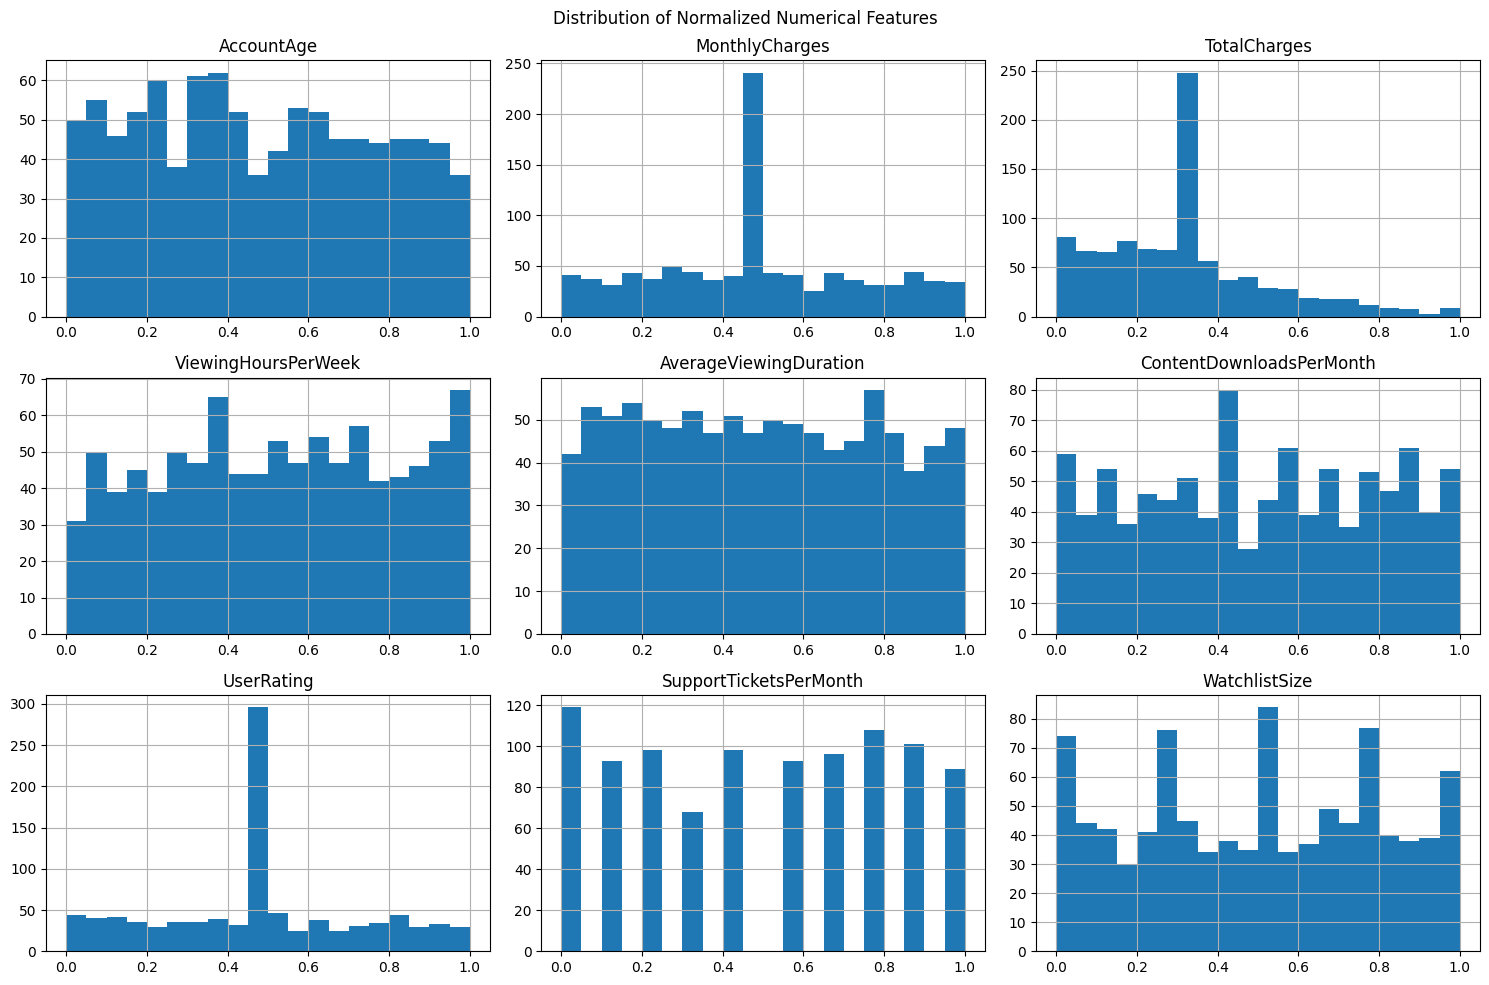

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

scaler = MinMaxScaler()

normalized_data = X.copy()
normalized_data[numeric_cols] = scaler.fit_transform(X[numeric_cols])

print("Normalized Data:")
display(normalized_data.head())

print("\nMinimum Values:")
print(normalized_data[numeric_cols].min())

print("\nMaximum Values:")
print(normalized_data[numeric_cols].max())

normalized_data[numeric_cols].hist(figsize=(15, 10), bins=20)
plt.suptitle("Distribution of Normalized Numerical Features")
plt.tight_layout()
plt.show()


STANDARDIZATION USING STANDARDSCALER

Standardized Data:


,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled
0,-0.461139,-0.266203,-0.519929,Basic,Electronic check,Yes,Movies,Yes,Tablet,-1.824776,-1.325680,0.021331,Comedy,5.684680e-01,0.867067,Female,0.435735,No,No
1,1.114128,0.127678,1.096366,Standard,Electronic check,Yes,TV Shows,No,Mobile,1.422680,0.242875,-0.258152,Comedy,-6.755895e-01,-0.496175,Male,-0.548281,No,Yes
2,-1.531131,0.000000,-1.356808,Standard,Credit card,Yes,TV Shows,No,Tablet,0.856388,-1.607876,0.300814,Fantasy,4.464047e-16,-0.155364,Male,0.295161,No,Yes
3,-0.104475,1.478627,0.552581,Basic,Credit card,Yes,Movies,No,Mobile,-1.638384,-0.911765,1.418747,Drama,-1.657539e+00,-0.496175,Male,0.014014,No,Yes
4,-0.906969,0.000000,-0.817384,Basic,Mailed check,No,TV Shows,No,Mobile,1.671428,0.071528,1.348876,Comedy,3.139129e-01,-0.155364,Female,0.857456,No,Yes



Mean of Standardized Columns:
AccountAge                 -0.0
MonthlyCharges             -0.0
TotalCharges               -0.0
ViewingHoursPerWeek         0.0
AverageViewingDuration     -0.0
ContentDownloadsPerMonth   -0.0
UserRating                  0.0
SupportTicketsPerMonth      0.0
WatchlistSize               0.0
dtype: float64

Standard Deviation of Standardized Columns:
AccountAge                  1.001
MonthlyCharges              1.001
TotalCharges                1.001
ViewingHoursPerWeek         1.001
AverageViewingDuration      1.001
ContentDownloadsPerMonth    1.001
UserRating                  1.001
SupportTicketsPerMonth      1.001
WatchlistSize               1.001
dtype: float64


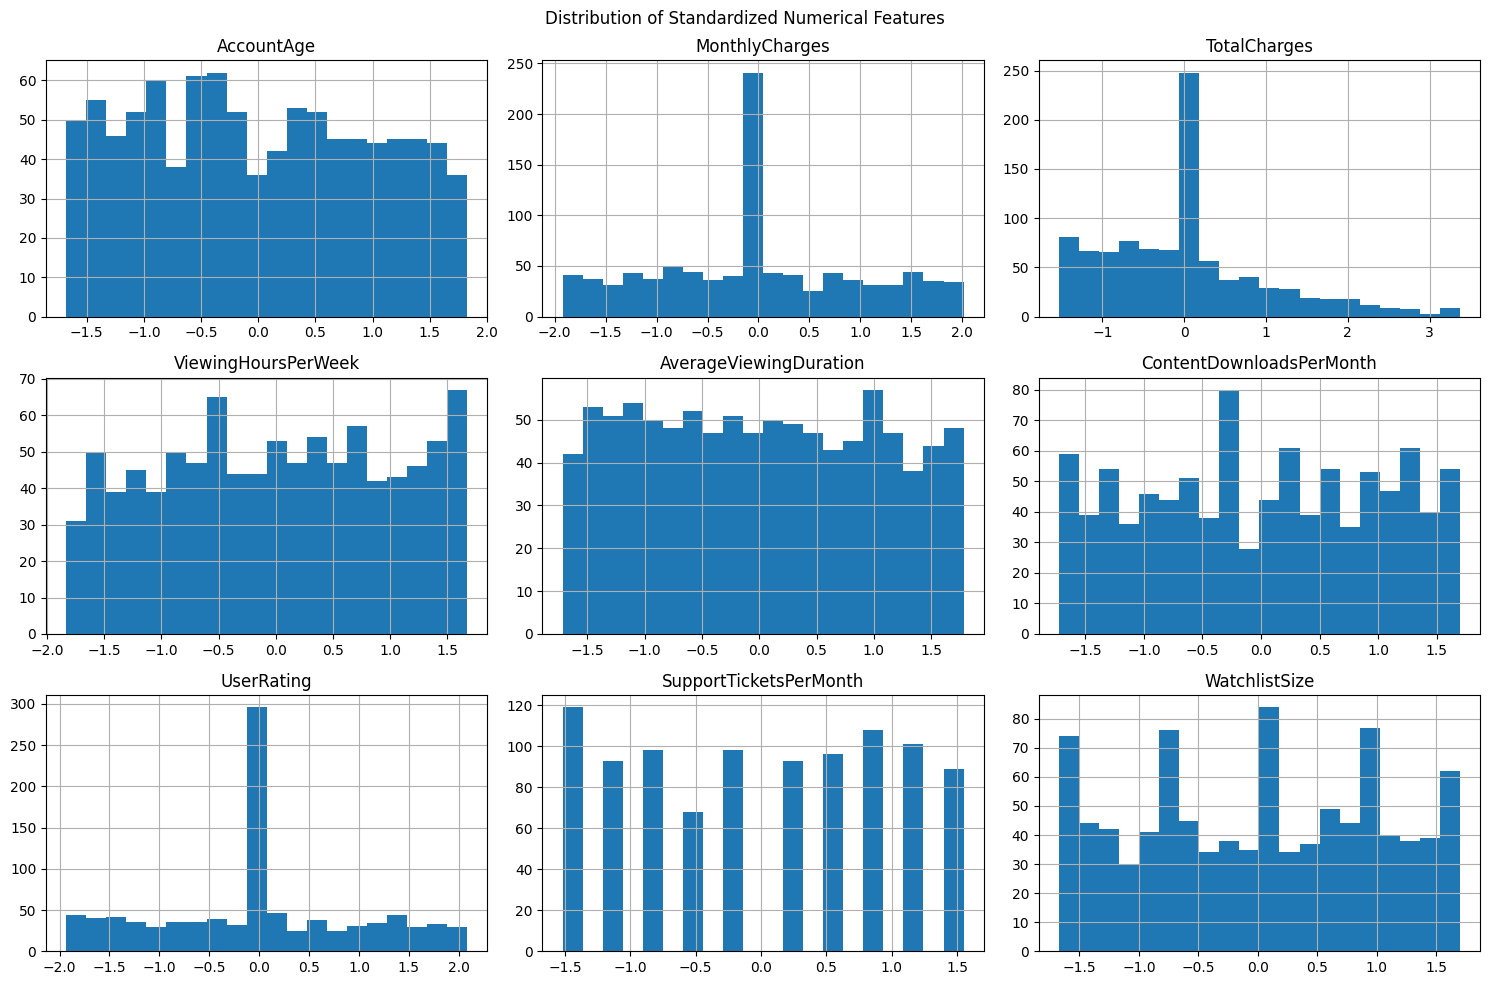

In [ ]:
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

standard_scaler = StandardScaler()

standardized_data = X.copy()
standardized_data[numeric_cols] = standard_scaler.fit_transform(X[numeric_cols])

print("Standardized Data:")
display(standardized_data.head())

print("\nMean of Standardized Columns:")
print(standardized_data[numeric_cols].mean().round(3))

print("\nStandard Deviation of Standardized Columns:")
print(standardized_data[numeric_cols].std().round(3))

standardized_data[numeric_cols].hist(figsize=(15, 10), bins=20)
plt.suptitle("Distribution of Standardized Numerical Features")
plt.tight_layout()
plt.show()


ENCODING CATEGORICAL VARIABLES

In [ ]:
encoded_data = pd.get_dummies(
X,
columns=categorical_cols,
drop_first=True,
dtype=int
)

print("Encoded Dataset:")
display(encoded_data.head())

print("\nOriginal Dataset Shape:", X.shape)
print("Encoded Dataset Shape:", encoded_data.shape)

print("\nEncoded Column Names:")
print(encoded_data.columns.tolist())


Encoded Dataset:


,AccountAge,MonthlyCharges,TotalCharges,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,UserRating,SupportTicketsPerMonth,WatchlistSize,SubscriptionType_Premium,...,DeviceRegistered_Mobile,DeviceRegistered_TV,DeviceRegistered_Tablet,GenrePreference_Comedy,GenrePreference_Drama,GenrePreference_Fantasy,GenrePreference_Sci-Fi,Gender_Male,ParentalControl_Yes,SubtitlesEnabled_Yes
0,42,11.321950,475.521914,0.386852,24.593361,25,3.489465,7,15,0,...,0,0,1,1,0,0,0,0,0,0
1,95,12.810915,1217.036887,37.123000,102.860795,21,2.251860,3,8,0,...,1,0,0,1,0,0,0,1,0,1
2,6,12.328262,91.583304,30.716944,10.512415,29,2.923945,4,14,0,...,0,0,1,0,0,1,0,1,0,1
3,54,17.917819,967.562224,2.495373,45.246834,45,1.275004,3,12,0,...,1,0,0,0,1,0,0,1,0,1
4,27,12.328262,339.057244,39.936910,94.310954,44,3.236230,4,18,0,...,1,0,0,1,0,0,0,0,0,1



Original Dataset Shape: (963, 19)
Encoded Dataset Shape: (963, 28)

Encoded Column Names:
['AccountAge', 'MonthlyCharges', 'TotalCharges', 'ViewingHoursPerWeek', 'AverageViewingDuration', 'ContentDownloadsPerMonth', 'UserRating', 'SupportTicketsPerMonth', 'WatchlistSize', 'SubscriptionType_Premium', 'SubscriptionType_Standard', 'PaymentMethod_Credit card', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'PaperlessBilling_Yes', 'ContentType_Movies', 'ContentType_TV Shows', 'MultiDeviceAccess_Yes', 'DeviceRegistered_Mobile', 'DeviceRegistered_TV', 'DeviceRegistered_Tablet', 'GenrePreference_Comedy', 'GenrePreference_Drama', 'GenrePreference_Fantasy', 'GenrePreference_Sci-Fi', 'Gender_Male', 'ParentalControl_Yes', 'SubtitlesEnabled_Yes']


CHECK SKEWNESS

Skewness of Numerical Features:
TotalCharges                0.908882
AccountAge                  0.090846
MonthlyCharges              0.083933
UserRating                  0.060065
AverageViewingDuration      0.051140
WatchlistSize              -0.015234
ContentDownloadsPerMonth   -0.026399
ViewingHoursPerWeek        -0.028468
SupportTicketsPerMonth     -0.042935
dtype: float64


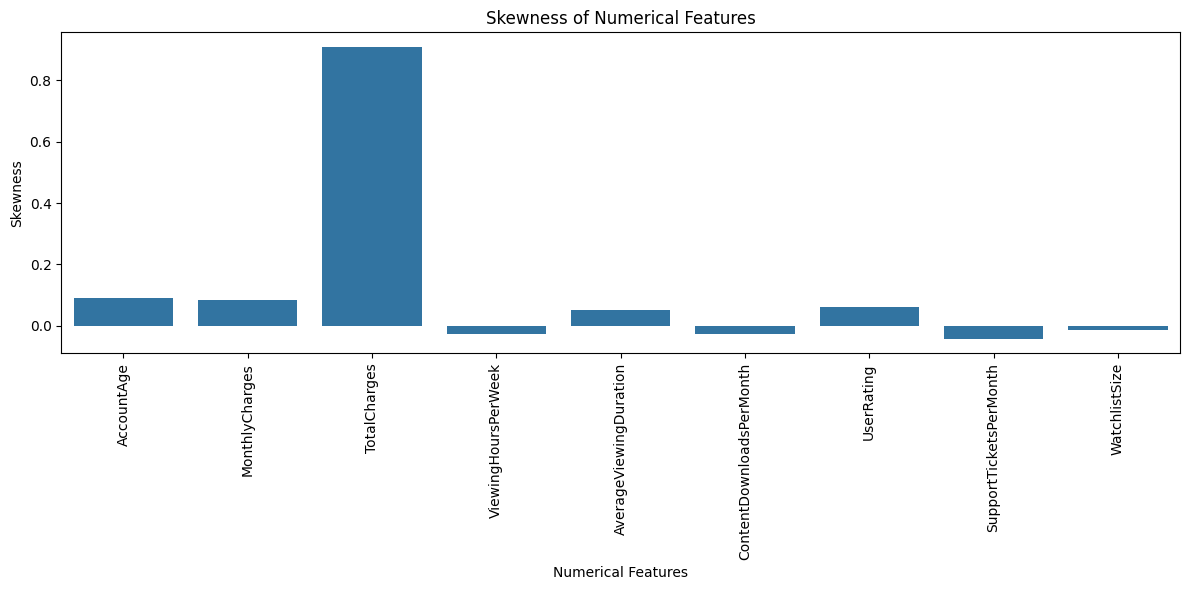

In [ ]:
skewness_values = X[numeric_cols].skew()

print("Skewness of Numerical Features:")
print(skewness_values.sort_values(ascending=False))

plt.figure(figsize=(12, 6))
sns.barplot(x=skewness_values.index, y=skewness_values.values)
plt.xticks(rotation=90)
plt.title("Skewness of Numerical Features")
plt.xlabel("Numerical Features")
plt.ylabel("Skewness")
plt.tight_layout()
plt.show()


FIX SKEWNESS USING LOG TRANSFORMATION

Skewness Before Transformation:
0.9088824229856254

Skewness After Transformation:
-1.3723336362308969


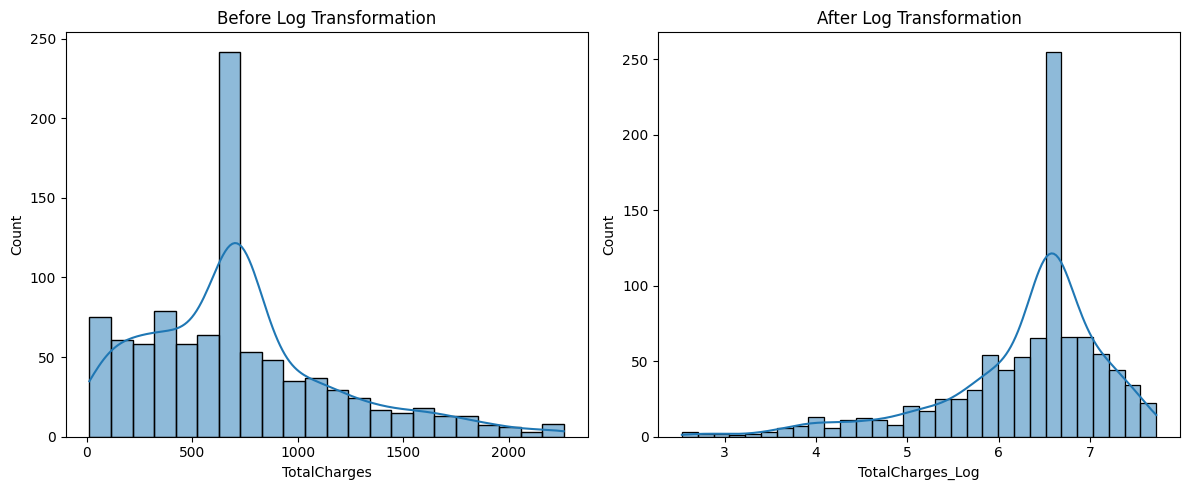

In [ ]:
# Check TotalCharges skewness before transformation

print("Skewness Before Transformation:")
print(X["TotalCharges"].skew())

# Apply Log Transformation

df["TotalCharges_Log"] = np.log1p(df["TotalCharges"])

# Check skewness after transformation

print("\nSkewness After Transformation:")
print(df["TotalCharges_Log"].skew())

# Visualize before and after transformation

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(X["TotalCharges"], kde=True)
plt.title("Before Log Transformation")

plt.subplot(1, 2, 2)
sns.histplot(df["TotalCharges_Log"], kde=True)
plt.title("After Log Transformation")

plt.tight_layout()
plt.show()


SAVE FEATURE ENGINEERING RESULTS

In [ ]:
# Save Normalized Dataset

normalized_data.to_csv("Week6_Normalized_Data.csv", index=False)

# Save Standardized Dataset

standardized_data.to_csv("Week6_Standardized_Data.csv", index=False)

# Save Encoded Dataset

encoded_data.to_csv("Week6_Encoded_Data.csv", index=False)

# Save Final Feature Engineering Dataset

df.to_csv("Week6_Feature_Engineering_Results.csv", index=False)

print("All Week 6 datasets saved successfully!")
print("\nFiles Created:")
print("1. Week6_Normalized_Data.csv")
print("2. Week6_Standardized_Data.csv")
print("3. Week6_Encoded_Data.csv")
print("4. Week6_Feature_Engineering_Results.csv")


All Week 6 datasets saved successfully!

Files Created:
1. Week6_Normalized_Data.csv
2. Week6_Standardized_Data.csv
3. Week6_Encoded_Data.csv
4. Week6_Feature_Engineering_Results.csv


FINAL VERIFICATION

In [ ]:
print("========== WEEK 6 FINAL VERIFICATION ==========")

print("\n1. Original Dataset Shape:")
print(df.shape)

print("\n2. Normalized Dataset Shape:")
print(normalized_data.shape)

print("\n3. Standardized Dataset Shape:")
print(standardized_data.shape)

print("\n4. Encoded Dataset Shape:")
print(encoded_data.shape)

print("\n5. Missing Values in Original Dataset:")
print(df.isnull().sum().sum())

print("\n6. Normalized Values Range:")
print("Minimum:", normalized_data[numeric_cols].min().min())
print("Maximum:", normalized_data[numeric_cols].max().max())

print("\n7. Standardized Values Mean:")
print(standardized_data[numeric_cols].mean().round(3))

print("\n8. TotalCharges Skewness Before Transformation:")
print(X["TotalCharges"].skew().round(3))

print("\n9. TotalCharges Skewness After Transformation:")
print(df["TotalCharges_Log"].skew().round(3))

print("\n========== WEEK 6 COMPLETED ==========")


========== WEEK 6 FINAL VERIFICATION ==========

1. Original Dataset Shape:
(963, 21)

2. Normalized Dataset Shape:
(963, 19)

3. Standardized Dataset Shape:
(963, 19)

4. Encoded Dataset Shape:
(963, 28)

5. Missing Values in Original Dataset:
0

6. Normalized Values Range:
Minimum: 0.0
Maximum: 1.0

7. Standardized Values Mean:
AccountAge                 -0.0
MonthlyCharges             -0.0
TotalCharges               -0.0
ViewingHoursPerWeek         0.0
AverageViewingDuration     -0.0
ContentDownloadsPerMonth   -0.0
UserRating                  0.0
SupportTicketsPerMonth      0.0
WatchlistSize               0.0
dtype: float64

8. TotalCharges Skewness Before Transformation:
0.909

9. TotalCharges Skewness After Transformation:
-1.372

========== WEEK 6 COMPLETED ==========


DOWNLOAD ALL OUTPUT FILES

In [ ]:
from google.colab import files

files.download("Week6_Normalized_Data.csv")
files.download("Week6_Standardized_Data.csv")
files.download("Week6_Encoded_Data.csv")
files.download("Week6_Feature_Engineering_Results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

WEEK 7 DIMENSIONALITY REDUCTION. IMPLEMENTING FEATURE SELECTION AND PCA. VISUALIZING VARIANCE

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

from google.colab import files

uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0])

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset Loaded Successfully!
Dataset Shape: (963, 21)


,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,Churn,TotalCharges_Log
0,42,11.321950,475.521914,Basic,Electronic check,Yes,Movies,Yes,Tablet,0.386852,...,25,Comedy,3.489465,7,Female,15,No,No,0,6.166514
1,95,12.810915,1217.036887,Standard,Electronic check,Yes,TV Shows,No,Mobile,37.123000,...,21,Comedy,2.251860,3,Male,8,No,Yes,0,7.104996
2,6,12.328262,91.583304,Standard,Credit card,Yes,TV Shows,No,Tablet,30.716944,...,29,Fantasy,2.923945,4,Male,14,No,Yes,1,4.528109
3,54,17.917819,967.562224,Basic,Credit card,Yes,Movies,No,Mobile,2.495373,...,45,Drama,1.275004,3,Male,12,No,Yes,0,6.875813
4,27,12.328262,339.057244,Basic,Mailed check,No,TV Shows,No,Mobile,39.936910,...,44,Comedy,3.236230,4,Female,18,No,Yes,0,5.829114


SEPARATE FEATURES AND TARGET

In [ ]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nNumerical Features:")
display(X.select_dtypes(include=np.number).head())

print("\nTarget Variable Distribution:")
print(y.value_counts())

print("\nTarget Variable Percentages:")
print((y.value_counts(normalize=True) * 100).round(2))


Input Features Shape: (963, 20)
Target Variable Shape: (963,)

Numerical Features:


,AccountAge,MonthlyCharges,TotalCharges,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,UserRating,SupportTicketsPerMonth,WatchlistSize,TotalCharges_Log
0,42,11.321950,475.521914,0.386852,24.593361,25,3.489465,7,15,6.166514
1,95,12.810915,1217.036887,37.123000,102.860795,21,2.251860,3,8,7.104996
2,6,12.328262,91.583304,30.716944,10.512415,29,2.923945,4,14,4.528109
3,54,17.917819,967.562224,2.495373,45.246834,45,1.275004,3,12,6.875813
4,27,12.328262,339.057244,39.936910,94.310954,44,3.236230,4,18,5.829114



Target Variable Distribution:
Churn
0    794
1    169
Name: count, dtype: int64

Target Variable Percentages:
Churn
0    82.45
1    17.55
Name: proportion, dtype: float64


FEATURE SELECTION USING CORRELATION

Feature Correlation with Churn:
AccountAge                 -0.218671
TotalCharges_Log           -0.159077
TotalCharges               -0.137320
AverageViewingDuration     -0.129019
ViewingHoursPerWeek        -0.126287
MonthlyCharges              0.118857
ContentDownloadsPerMonth   -0.115284
SupportTicketsPerMonth      0.093930
WatchlistSize               0.033328
UserRating                  0.002044
Name: Churn, dtype: float64


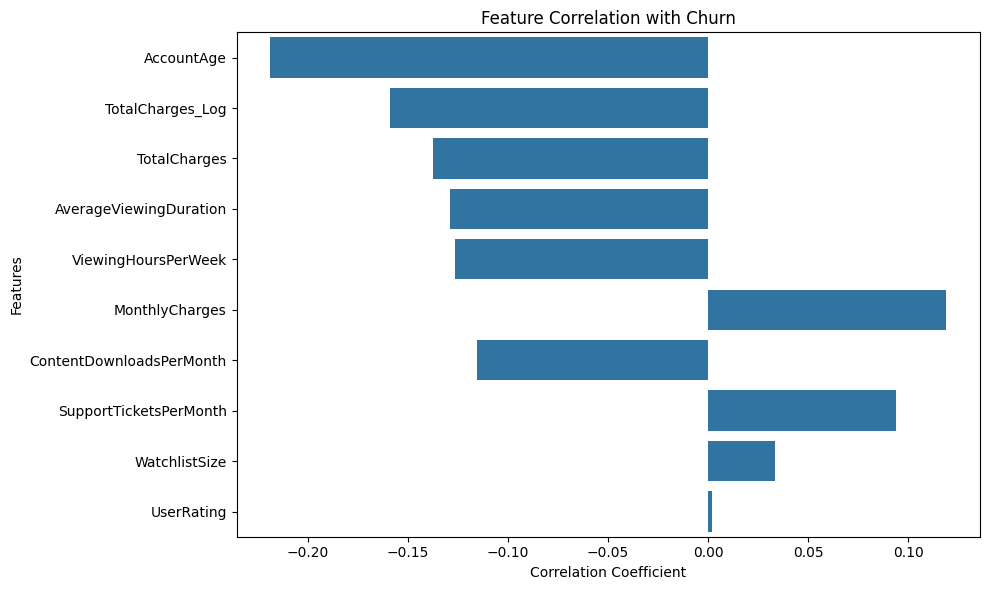

In [ ]:
# Select numerical features

numeric_data = df.select_dtypes(include=np.number)

# Calculate correlation with Churn

correlation = numeric_data.corr()["Churn"].drop("Churn")

# Sort correlation values

correlation = correlation.sort_values(key=abs, ascending=False)

print("Feature Correlation with Churn:")
print(correlation)

# Visualize correlation

plt.figure(figsize=(10, 6))
sns.barplot(x=correlation.values, y=correlation.index)
plt.title("Feature Correlation with Churn")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


CORRELATION HEATMAP

Correlation Matrix:


,AccountAge,MonthlyCharges,TotalCharges,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,UserRating,SupportTicketsPerMonth,WatchlistSize,Churn,TotalCharges_Log
AccountAge,1.00,0.03,0.75,-0.04,-0.04,-0.03,0.00,0.01,-0.03,-0.22,0.75
MonthlyCharges,0.03,1.00,0.40,0.00,-0.01,-0.01,0.03,0.01,0.01,0.12,0.29
TotalCharges,0.75,0.40,1.00,-0.00,-0.06,-0.03,0.04,-0.01,-0.02,-0.14,0.86
ViewingHoursPerWeek,-0.04,0.00,-0.00,1.00,0.01,-0.00,-0.00,-0.00,-0.01,-0.13,-0.03
AverageViewingDuration,-0.04,-0.01,-0.06,0.01,1.00,0.04,0.05,0.03,0.05,-0.13,-0.03
ContentDownloadsPerMonth,-0.03,-0.01,-0.03,-0.00,0.04,1.00,0.05,-0.01,-0.03,-0.12,-0.03
UserRating,0.00,0.03,0.04,-0.00,0.05,0.05,1.00,-0.01,-0.01,0.00,0.01
SupportTicketsPerMonth,0.01,0.01,-0.01,-0.00,0.03,-0.01,-0.01,1.00,-0.01,0.09,0.01
WatchlistSize,-0.03,0.01,-0.02,-0.01,0.05,-0.03,-0.01,-0.01,1.00,0.03,-0.01
Churn,-0.22,0.12,-0.14,-0.13,-0.13,-0.12,0.00,0.09,0.03,1.00,-0.16


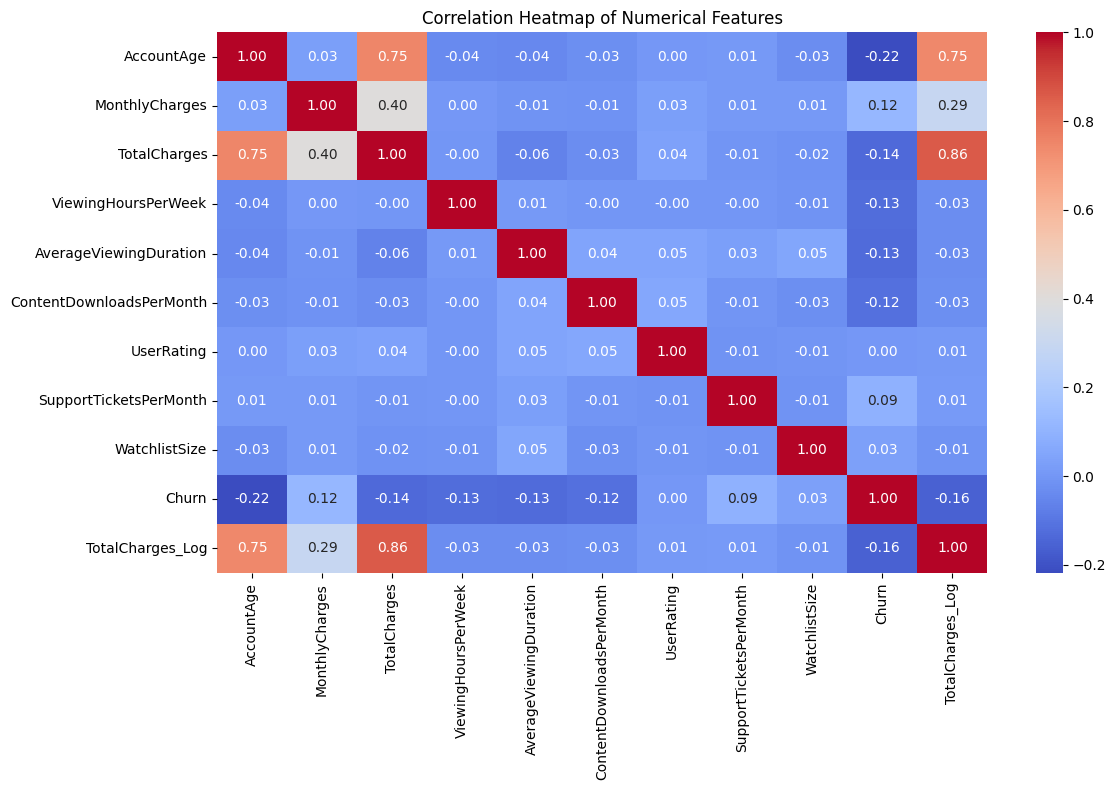

In [ ]:
# Select numerical columns

numeric_data = df.select_dtypes(include=np.number)

# Calculate correlation matrix

correlation_matrix = numeric_data.corr()

# Display correlation matrix

print("Correlation Matrix:")
display(correlation_matrix.round(2))

# Plot heatmap

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


COVARIANCE MATRIX AND VISUALIZATION

Covariance Matrix:


,AccountAge,MonthlyCharges,TotalCharges,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,UserRating,SupportTicketsPerMonth,WatchlistSize,Churn,TotalCharges_Log
AccountAge,1133.17,3.47,11574.51,-14.85,-72.04,-12.74,0.09,0.94,-7.38,-2.80,22.59
MonthlyCharges,3.47,14.31,687.67,0.05,-1.91,-0.77,0.10,0.07,0.19,0.17,1.00
TotalCharges,11574.51,687.67,210692.79,-4.75,-1476.20,-205.81,16.90,-8.13,-55.02,-23.99,354.22
ViewingHoursPerWeek,-14.85,0.05,-4.75,128.10,3.08,-0.69,-0.01,-0.02,-0.96,-0.54,-0.33
AverageViewingDuration,-72.04,-1.91,-1476.20,3.08,2492.38,31.44,2.26,3.76,17.58,-2.45,-1.48
ContentDownloadsPerMonth,-12.74,-0.77,-205.81,-0.69,31.44,205.05,0.78,-0.35,-2.85,-0.63,-0.33
UserRating,0.09,0.10,16.90,-0.01,2.26,0.78,0.99,-0.03,-0.06,0.00,0.01
SupportTicketsPerMonth,0.94,0.07,-8.13,-0.02,3.76,-0.35,-0.03,8.62,-0.25,0.10,0.03
WatchlistSize,-7.38,0.19,-55.02,-0.96,17.58,-2.85,-0.06,-0.25,50.66,0.09,-0.08
Churn,-2.80,0.17,-23.99,-0.54,-2.45,-0.63,0.00,0.10,0.09,0.14,-0.05


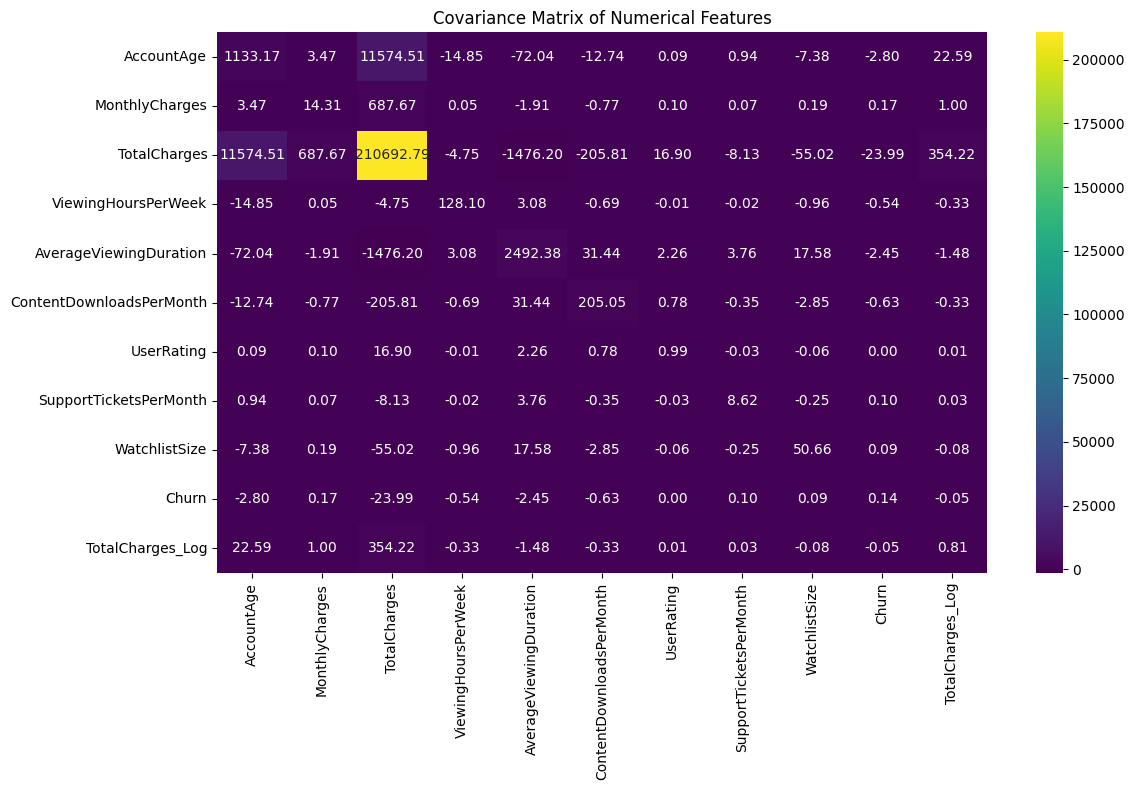

In [ ]:
# Select numerical columns

numeric_data = df.select_dtypes(include=np.number)

# Calculate covariance matrix

covariance_matrix = numeric_data.cov()

print("Covariance Matrix:")
display(covariance_matrix.round(2))

# Visualize covariance matrix

plt.figure(figsize=(12, 8))
sns.heatmap(covariance_matrix, annot=True, fmt=".2f", cmap="viridis")
plt.title("Covariance Matrix of Numerical Features")
plt.tight_layout()
plt.show()


ENCODE CATEGORICAL VARIABLES FOR PCA

In [ ]:
# Separate input features and target

X = df.drop(columns=["Churn"])
y = df["Churn"]

# Encode categorical variables

X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded Dataset Shape:", X_encoded.shape)

print("\nFirst 5 Rows of Encoded Dataset:")
display(X_encoded.head())

# Check for missing values

print("\nMissing Values:", X_encoded.isnull().sum().sum())


Encoded Dataset Shape: (963, 29)

First 5 Rows of Encoded Dataset:


,AccountAge,MonthlyCharges,TotalCharges,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,UserRating,SupportTicketsPerMonth,WatchlistSize,TotalCharges_Log,...,DeviceRegistered_Mobile,DeviceRegistered_TV,DeviceRegistered_Tablet,GenrePreference_Comedy,GenrePreference_Drama,GenrePreference_Fantasy,GenrePreference_Sci-Fi,Gender_Male,ParentalControl_Yes,SubtitlesEnabled_Yes
0,42,11.321950,475.521914,0.386852,24.593361,25,3.489465,7,15,6.166514,...,0,0,1,1,0,0,0,0,0,0
1,95,12.810915,1217.036887,37.123000,102.860795,21,2.251860,3,8,7.104996,...,1,0,0,1,0,0,0,1,0,1
2,6,12.328262,91.583304,30.716944,10.512415,29,2.923945,4,14,4.528109,...,0,0,1,0,0,1,0,1,0,1
3,54,17.917819,967.562224,2.495373,45.246834,45,1.275004,3,12,6.875813,...,1,0,0,0,1,0,0,1,0,1
4,27,12.328262,339.057244,39.936910,94.310954,44,3.236230,4,18,5.829114,...,1,0,0,1,0,0,0,0,0,1



Missing Values: 0


STANDARDIZE VARIABLES FOR PCA

In [ ]:
# Standardize the encoded features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

print("Standardization Completed Successfully!")
print("Scaled Dataset Shape:", X_scaled.shape)

# Display first 5 rows

scaled_df = pd.DataFrame(
X_scaled,
columns=X_encoded.columns
)

display(scaled_df.head())

# Check mean and standard deviation

print("\nMean of Scaled Features:")
print(np.round(X_scaled.mean(axis=0)[:10], 3))

print("\nStandard Deviation of Scaled Features:")
print(np.round(X_scaled.std(axis=0)[:10], 3))


Standardization Completed Successfully!
Scaled Dataset Shape: (963, 29)


,AccountAge,MonthlyCharges,TotalCharges,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,UserRating,SupportTicketsPerMonth,WatchlistSize,TotalCharges_Log,...,DeviceRegistered_Mobile,DeviceRegistered_TV,DeviceRegistered_Tablet,GenrePreference_Comedy,GenrePreference_Drama,GenrePreference_Fantasy,GenrePreference_Sci-Fi,Gender_Male,ParentalControl_Yes,SubtitlesEnabled_Yes
0,-0.461139,-0.266203,-0.519929,-1.824776,-1.325680,0.021331,5.684680e-01,0.867067,0.435735,-0.133034,...,-0.762418,-0.593741,2.828427,1.465285,-0.487636,-0.487636,-0.35726,-1.233265,-0.8429,-3.322273
1,1.114128,0.127678,1.096366,1.422680,0.242875,-0.258152,-6.755895e-01,-0.496175,-0.548281,0.912575,...,1.311617,-0.593741,-0.353553,1.465285,-0.487636,-0.487636,-0.35726,0.810856,-0.8429,0.300999
2,-1.531131,0.000000,-1.356808,0.856388,-1.607876,0.300814,4.464047e-16,-0.155364,0.295161,-1.958462,...,-0.762418,-0.593741,2.828427,-0.682461,-0.487636,2.050709,-0.35726,0.810856,-0.8429,0.300999
3,-0.104475,1.478627,0.552581,-1.638384,-0.911765,1.418747,-1.657539e+00,-0.496175,0.014014,0.657231,...,1.311617,-0.593741,-0.353553,-0.682461,2.050709,-0.487636,-0.35726,0.810856,-0.8429,0.300999
4,-0.906969,0.000000,-0.817384,1.671428,0.071528,1.348876,3.139129e-01,-0.155364,0.857456,-0.508948,...,1.311617,-0.593741,-0.353553,1.465285,-0.487636,-0.487636,-0.35726,-1.233265,-0.8429,0.300999



Mean of Scaled Features:
[-0. -0. -0.  0. -0. -0.  0.  0.  0. -0.]

Standard Deviation of Scaled Features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


APPLY PCA AND CALCULATE EXPLAINED VARIANCE

In [ ]:
# Apply PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Calculate explained variance

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Display explained variance

pca_results = pd.DataFrame({
"Principal Component": [
f"PC{i+1}" for i in range(len(explained_variance))
],
"Explained Variance Ratio": explained_variance,
"Cumulative Explained Variance": cumulative_variance
})

print("PCA Explained Variance Results:")
display(pca_results.round(4))

print("\nTotal Components:", len(explained_variance))
print("Total Explained Variance:", round(cumulative_variance[-1] * 100, 2), "%")


PCA Explained Variance Results:


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.0939,0.0939
1,PC2,0.0572,0.1510
2,PC3,0.0556,0.2066
3,PC4,0.0519,0.2585
4,PC5,0.0499,0.3085
5,PC6,0.0474,0.3559
6,PC7,0.0458,0.4017
7,PC8,0.0431,0.4448
8,PC9,0.0417,0.4865
9,PC10,0.0410,0.5275



Total Components: 29
Total Explained Variance: 100.0 %


VISUALIZE EXPLAINED VARIANCE

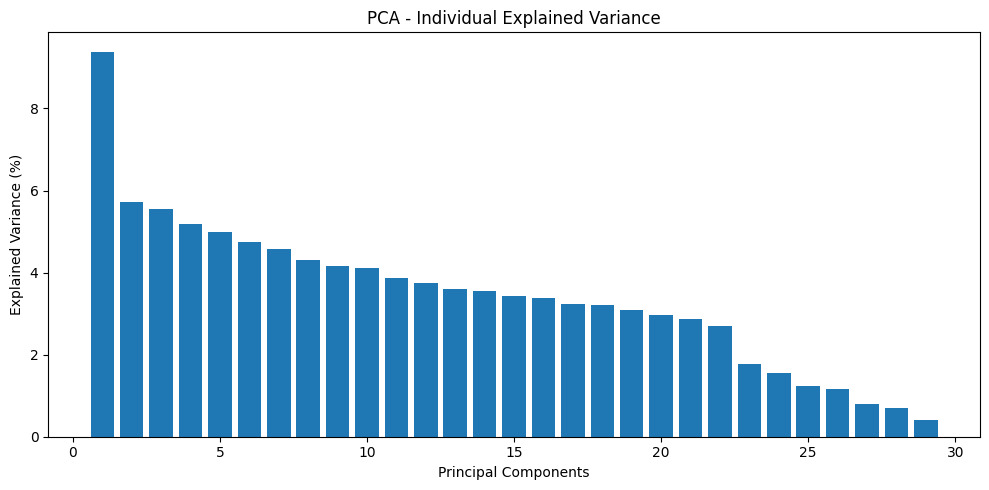

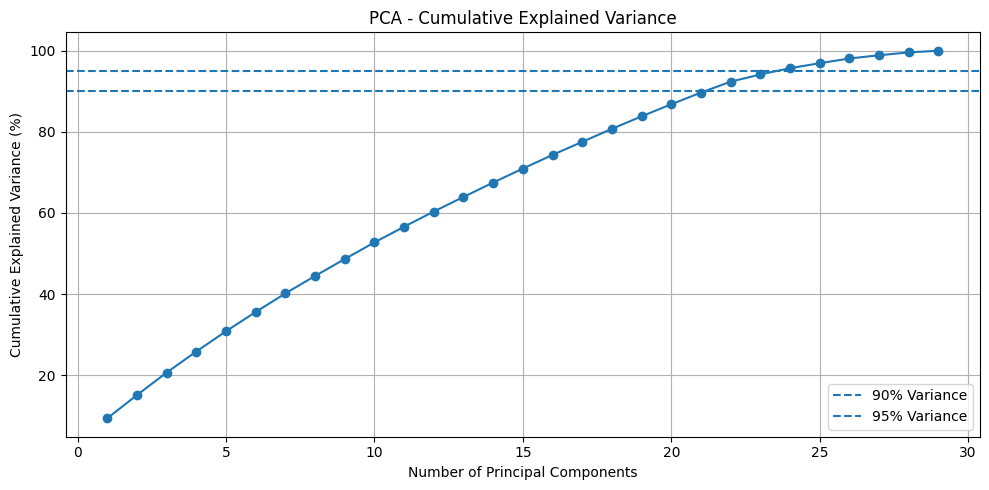

Components required for 90% variance: 22
Components required for 95% variance: 24


In [ ]:
# Plot Individual Explained Variance

plt.figure(figsize=(10, 5))
plt.bar(
range(1, len(explained_variance) + 1),
explained_variance * 100
)
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA - Individual Explained Variance")
plt.tight_layout()
plt.show()

# Plot Cumulative Explained Variance

plt.figure(figsize=(10, 5))
plt.plot(
range(1, len(cumulative_variance) + 1),
cumulative_variance * 100,
marker="o"
)
plt.axhline(y=90, linestyle="--", label="90% Variance")
plt.axhline(y=95, linestyle="--", label="95% Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Find components required for 90% and 95% variance

n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components required for 90% variance:", n_components_90)
print("Components required for 95% variance:", n_components_95)


REDUCE DIMENSIONS USING PCA

In [ ]:
# Apply PCA with 90% explained variance

pca_reduced = PCA(n_components=0.90)
X_reduced = pca_reduced.fit_transform(X_scaled)

# Create reduced dataset

pca_columns = [
f"PC{i+1}" for i in range(X_reduced.shape[1])
]

pca_df = pd.DataFrame(
X_reduced,
columns=pca_columns
)

# Add original target column

pca_df["Churn"] = y.reset_index(drop=True)

print("PCA Dimensionality Reduction Completed!")

print("\nOriginal Feature Count:", X_encoded.shape[1])
print("Reduced Feature Count:", X_reduced.shape[1])
print("Reduced Dataset Shape:", pca_df.shape)

print("\nReduced Dataset:")
display(pca_df.head())

print(
"\nExplained Variance Retained:",
round(pca_reduced.explained_variance_ratio_.sum() * 100, 2),
"%"
)


PCA Dimensionality Reduction Completed!

Original Feature Count: 29
Reduced Feature Count: 22
Reduced Dataset Shape: (963, 23)

Reduced Dataset:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,Churn
0,-0.543672,-2.230360,-0.617973,-2.201159,-1.713062,0.199498,0.414946,1.587233,-3.721719,0.422064,...,-0.004827,2.095918,0.783478,-0.498574,-0.153135,-1.314201,0.149287,0.096213,1.539373,0
1,1.627239,-0.225080,0.987976,0.947121,0.985263,3.124649,-0.536486,0.249015,-1.390553,0.421935,...,-0.316471,-1.630852,-0.856611,1.080383,0.363048,0.687120,0.014766,0.521235,0.683996,0
2,-2.726254,-0.249028,-1.031821,2.586512,-0.055718,-0.850616,1.675997,0.692301,-1.664841,-0.318987,...,-0.455764,0.050687,-1.138665,0.837855,0.032759,1.875942,-0.542329,-0.674702,0.691330,1
3,0.842122,0.362530,-2.189198,-0.938914,1.080944,-0.810877,-0.919741,-1.328510,-0.780432,1.477108,...,0.413743,-0.592500,-0.167656,0.874543,-1.249758,0.655404,-1.600566,-2.194225,0.146239,0
4,-1.571395,0.467974,0.687153,-0.229537,0.983790,2.555485,-2.270772,1.450487,1.365004,-1.476725,...,0.954141,-0.173917,0.711052,0.461294,-0.639893,0.674775,-0.257393,-0.636048,0.566494,0



Explained Variance Retained: 92.37 %


VISUALIZE PCA RESULTS

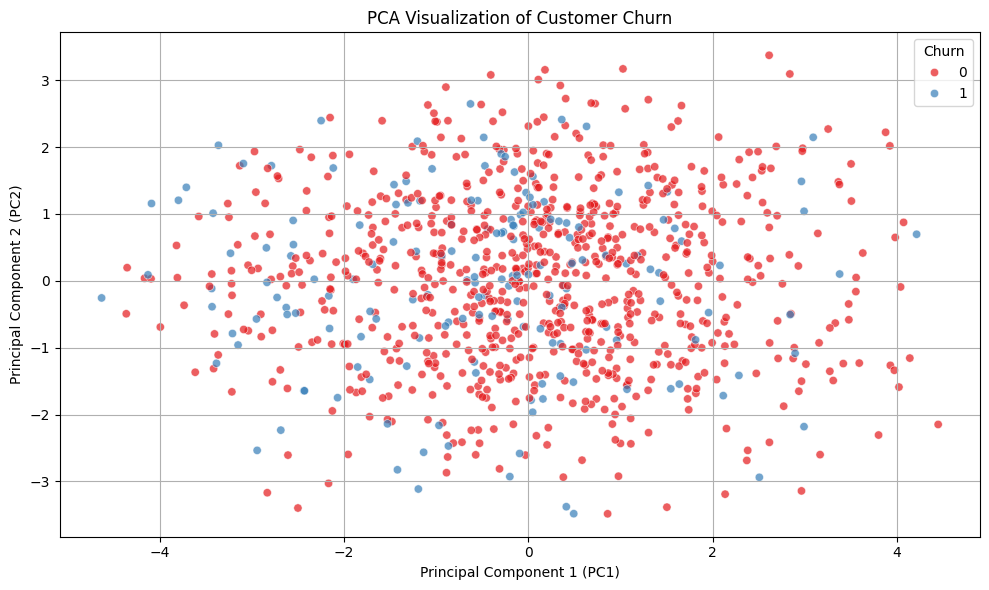

In [ ]:
# Visualize PCA Results Using PC1 and PC2

plt.figure(figsize=(10, 6))

sns.scatterplot(
data=pca_df,
x="PC1",
y="PC2",
hue="Churn",
palette="Set1",
alpha=0.7
)

plt.title("PCA Visualization of Customer Churn")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend(title="Churn")
plt.grid(True)
plt.tight_layout()
plt.show()


ANALYZE PCA FEATURE LOADINGS

PCA Feature Loadings:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22
AccountAge,0.514,0.016,-0.012,-0.003,0.032,0.044,0.088,0.037,-0.032,-0.120,...,-0.110,0.113,-0.188,0.134,-0.153,0.038,0.037,0.056,0.096,0.143
MonthlyCharges,0.243,0.039,-0.004,-0.018,0.021,-0.001,-0.213,-0.016,0.064,0.279,...,0.191,-0.288,0.389,-0.326,0.351,-0.109,-0.077,-0.177,-0.219,-0.292
TotalCharges,0.573,0.036,-0.053,-0.033,0.049,0.015,-0.033,0.038,0.010,-0.025,...,0.014,-0.053,0.002,0.006,0.014,0.033,0.021,-0.056,-0.003,-0.029
ViewingHoursPerWeek,-0.024,0.062,0.106,0.102,0.003,0.063,-0.171,-0.047,0.139,-0.339,...,0.158,-0.293,-0.157,0.160,0.550,0.062,0.266,0.139,0.401,0.073
AverageViewingDuration,-0.049,-0.003,0.119,0.006,0.138,0.070,-0.022,0.143,0.221,-0.011,...,-0.099,-0.414,-0.136,-0.177,-0.232,-0.286,-0.189,-0.251,0.458,-0.094
ContentDownloadsPerMonth,-0.030,-0.034,0.058,0.027,0.088,0.002,-0.053,0.143,0.028,0.048,...,-0.043,-0.058,0.004,0.491,0.191,-0.385,0.310,-0.179,-0.250,0.086
UserRating,0.015,-0.040,-0.076,-0.033,-0.065,-0.089,-0.106,0.196,0.065,-0.123,...,0.235,-0.368,0.002,-0.123,-0.134,0.351,-0.071,0.544,-0.151,0.094
SupportTicketsPerMonth,0.003,-0.068,0.026,-0.097,0.035,0.069,0.073,0.070,0.155,-0.313,...,-0.394,0.027,0.591,-0.281,-0.045,-0.225,0.259,0.182,0.026,0.321
WatchlistSize,-0.017,-0.052,-0.031,-0.015,0.065,-0.060,0.159,0.171,0.245,0.159,...,0.201,-0.083,0.223,0.246,0.093,0.347,-0.001,-0.257,-0.149,0.438
TotalCharges_Log,0.564,0.041,-0.008,-0.029,0.046,0.016,0.009,0.040,-0.015,-0.040,...,-0.013,-0.010,-0.033,0.031,-0.050,-0.008,0.026,-0.044,0.019,0.025



Top 10 Features Contributing to PC1:


,Feature,Absolute Loading
0,TotalCharges,0.573
1,TotalCharges_Log,0.564
2,AccountAge,0.514
3,MonthlyCharges,0.243
4,DeviceRegistered_TV,0.098
5,DeviceRegistered_Mobile,0.064
6,ParentalControl_Yes,0.064
7,PaperlessBilling_Yes,0.057
8,AverageViewingDuration,0.049
9,ContentDownloadsPerMonth,0.030


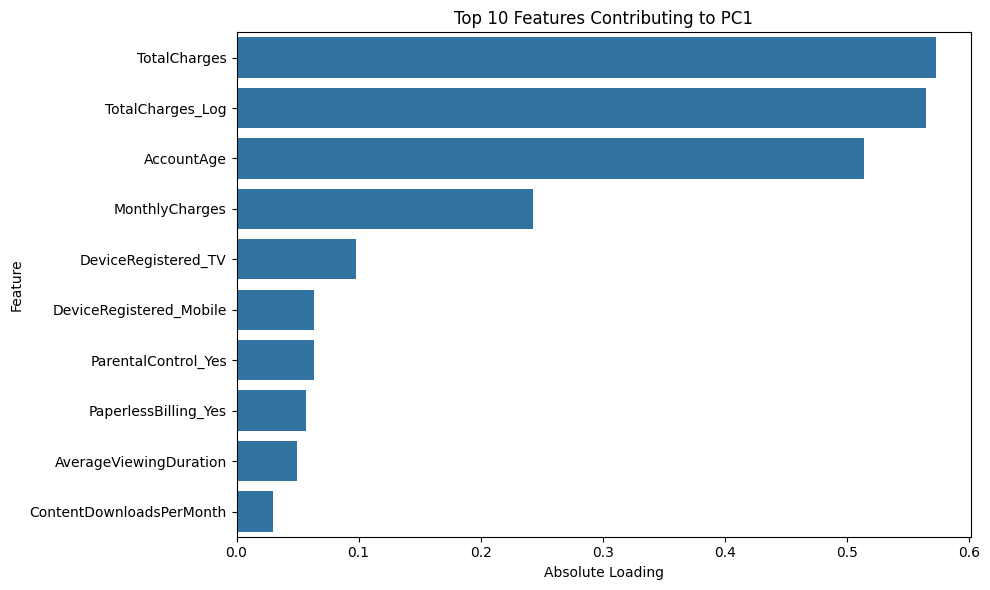

In [ ]:
# Calculate PCA Feature Loadings

loadings = pd.DataFrame(
pca_reduced.components_.T,
index=X_encoded.columns,
columns=[f"PC{i+1}" for i in range(pca_reduced.n_components_)]
)

print("PCA Feature Loadings:")
display(loadings.round(3))

# Display the top 10 features contributing to PC1

print("\nTop 10 Features Contributing to PC1:")

pc1_loadings = loadings["PC1"].abs().sort_values(ascending=False).head(10)

display(
pd.DataFrame({
"Feature": pc1_loadings.index,
"Absolute Loading": pc1_loadings.values
}).round(3)
)

# Visualize top 10 PC1 loadings

plt.figure(figsize=(10, 6))
sns.barplot(
x=pc1_loadings.values,
y=pc1_loadings.index
)
plt.title("Top 10 Features Contributing to PC1")
plt.xlabel("Absolute Loading")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


FEATURE SELECTION USING MUTUAL INFORMATION

Top 15 Features Related to Customer Churn:


,Feature,Mutual Information Score
0,AccountAge,0.0458
9,TotalCharges_Log,0.0228
2,TotalCharges,0.0214
1,MonthlyCharges,0.0163
3,ViewingHoursPerWeek,0.0149
5,ContentDownloadsPerMonth,0.0114
8,WatchlistSize,0.0091
14,PaymentMethod_Mailed check,0.0020
28,SubtitlesEnabled_Yes,0.0016
19,DeviceRegistered_Mobile,0.0012


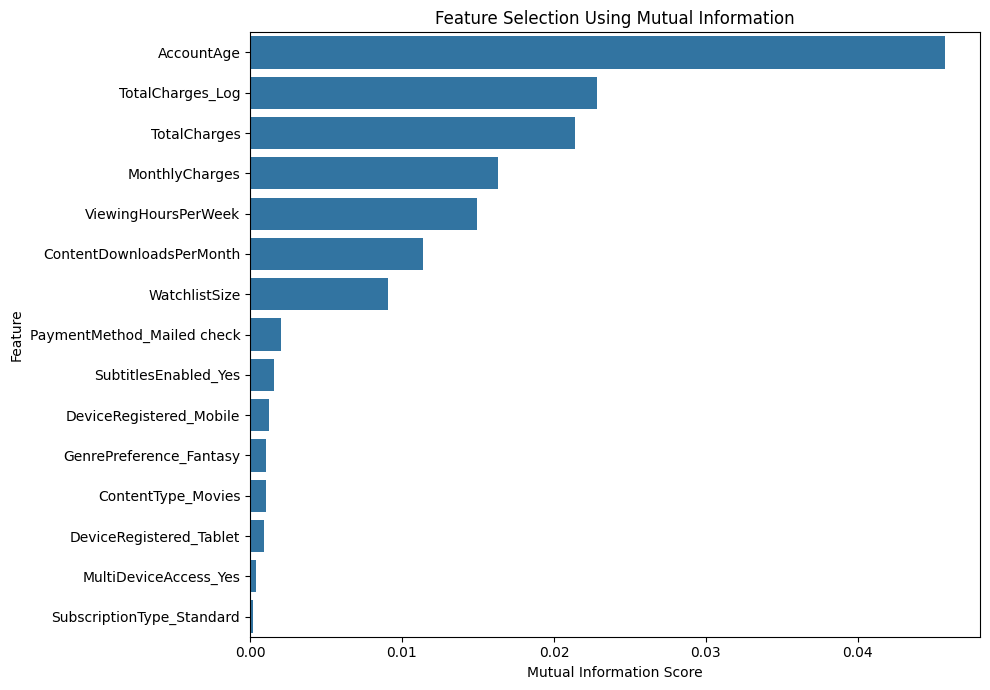

In [ ]:
# Feature Selection Using Mutual Information

from sklearn.feature_selection import mutual_info_classif

# Identify categorical and numerical features

continuous_cols = X.select_dtypes(include=np.number).columns.tolist()

discrete_mask = [
col not in continuous_cols
for col in X_encoded.columns
]

# Calculate Mutual Information

mi_scores = mutual_info_classif(
X_encoded,
y,
discrete_features=discrete_mask,
random_state=42
)

# Create results DataFrame

mi_results = pd.DataFrame({
"Feature": X_encoded.columns,
"Mutual Information Score": mi_scores
})

# Sort features by importance

mi_results = mi_results.sort_values(
by="Mutual Information Score",
ascending=False
)

print("Top 15 Features Related to Customer Churn:")
display(mi_results.head(15).round(4))

# Visualize top 15 features

top_features = mi_results.head(15)

plt.figure(figsize=(10, 7))
sns.barplot(
data=top_features,
x="Mutual Information Score",
y="Feature"
)
plt.title("Feature Selection Using Mutual Information")
plt.tight_layout()
plt.show()


SAVE PCA AND FEATURE SELECTION RESULTS

In [ ]:
# Save PCA Reduced Dataset

pca_df.to_csv("Week7_PCA_Reduced_Dataset.csv", index=False)

# Save PCA Explained Variance Results

pca_results.to_csv("Week7_PCA_Explained_Variance.csv", index=False)

# Save PCA Feature Loadings

loadings.to_csv("Week7_PCA_Feature_Loadings.csv")

# Save Mutual Information Results

mi_results.to_csv("Week7_Mutual_Information_Features.csv", index=False)

# Save Correlation Results

correlation.to_csv("Week7_Feature_Correlation.csv", header=["Correlation"])

# Save Covariance Matrix

covariance_matrix.to_csv("Week7_Covariance_Matrix.csv")

print("All Week 7 output files saved successfully!")
print("\nFiles Created:")
print("1. Week7_PCA_Reduced_Dataset.csv")
print("2. Week7_PCA_Explained_Variance.csv")
print("3. Week7_PCA_Feature_Loadings.csv")
print("4. Week7_Mutual_Information_Features.csv")
print("5. Week7_Feature_Correlation.csv")
print("6. Week7_Covariance_Matrix.csv")


All Week 7 output files saved successfully!

Files Created:
1. Week7_PCA_Reduced_Dataset.csv
2. Week7_PCA_Explained_Variance.csv
3. Week7_PCA_Feature_Loadings.csv
4. Week7_Mutual_Information_Features.csv
5. Week7_Feature_Correlation.csv
6. Week7_Covariance_Matrix.csv


FINAL VERIFICATION

In [ ]:
print("========== WEEK 7 FINAL VERIFICATION ==========")

print("\n1. Original Dataset Shape:")
print(df.shape)

print("\n2. Encoded Dataset Shape:")
print(X_encoded.shape)

print("\n3. PCA Reduced Dataset Shape:")
print(pca_df.shape)

print("\n4. Original Number of Features:")
print(X_encoded.shape[1])

print("\n5. Reduced Number of Principal Components:")
print(X_reduced.shape[1])

print("\n6. Total Explained Variance:")
print(round(pca_reduced.explained_variance_ratio_.sum() * 100, 2), "%")

print("\n7. Missing Values in PCA Dataset:")
print(pca_df.isnull().sum().sum())

print("\n8. Top 5 Features Based on Mutual Information:")
display(mi_results.head(5).round(4))

print("\n9. Output Files Saved Successfully!")

print("\n========== WEEK 7 COMPLETED ==========")


========== WEEK 7 FINAL VERIFICATION ==========

1. Original Dataset Shape:
(963, 21)

2. Encoded Dataset Shape:
(963, 29)

3. PCA Reduced Dataset Shape:
(963, 23)

4. Original Number of Features:
29

5. Reduced Number of Principal Components:
22

6. Total Explained Variance:
92.37 %

7. Missing Values in PCA Dataset:
0

8. Top 5 Features Based on Mutual Information:


,Feature,Mutual Information Score
0,AccountAge,0.0458
9,TotalCharges_Log,0.0228
2,TotalCharges,0.0214
1,MonthlyCharges,0.0163
3,ViewingHoursPerWeek,0.0149



9. Output Files Saved Successfully!

========== WEEK 7 COMPLETED ==========


DOWNLOAD ALL THE OUTPUT FILES

In [ ]:
from google.colab import files

files.download("Week7_PCA_Reduced_Dataset.csv")
files.download("Week7_PCA_Explained_Variance.csv")
files.download("Week7_PCA_Feature_Loadings.csv")
files.download("Week7_Mutual_Information_Features.csv")
files.download("Week7_Feature_Correlation.csv")
files.download("Week7_Covariance_Matrix.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>